# Week 4 — End-to-End Image Retrieval Experiments

## Dataset

**Questions:** What is the evaluation unit? How many queries and paintings are present? How many paintings are known versus unknown? Are query rows, ground truth, companion files, and BBDD identifiers aligned?

**Goal:** establish the exact evaluation population before building or tuning the retrieval pipeline.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for directory in (start, *start.parents):
        if (directory / "data").is_dir() and (directory / "src").is_dir():
            return directory
    raise FileNotFoundError("Could not find the project root containing data/ and src/")


ROOT = find_project_root()
DATA_DIR = ROOT / "data"
QSD_DIR = DATA_DIR / "qsd1_w4"

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import load_ground_truth, load_image_dataset

qsd = load_image_dataset(QSD_DIR)
bbdd = load_image_dataset(DATA_DIR / "BBDD")
ground_truth = load_ground_truth(QSD_DIR / "gt_corresps.pkl")

print(f"Project root: {ROOT}")

Project root: /Users/femiloye/Desktop/MCV/Materials/C1/project


In [2]:
# Validate the row contract: query position i must correspond to ground_truth[i].
assert len(qsd) == len(ground_truth), (len(qsd), len(ground_truth))
assert np.all(np.diff(qsd.ids) > 0), "Query IDs are not strictly increasing"
assert all(len(row) in (1, 2) for row in ground_truth), "Expected one or two paintings per query"

bbdd_ids = set(map(int, bbdd.ids))
known_ids = [painting_id for row in ground_truth for painting_id in row if painting_id != -1]
unknown_count = sum(painting_id == -1 for row in ground_truth for painting_id in row)
missing_bbdd_ids = sorted(set(known_ids) - bbdd_ids)
assert not missing_bbdd_ids, f"Ground-truth IDs missing from BBDD: {missing_bbdd_ids}"

inventory = pd.DataFrame(
    {
        "query_id": qsd.ids.astype(int),
        "paintings": [len(row) for row in ground_truth],
        "known": [sum(painting_id != -1 for painting_id in row) for row in ground_truth],
        "unknown": [sum(painting_id == -1 for painting_id in row) for row in ground_truth],
        "jpg": [path.name for path in qsd.paths],
        "png_present": [path.with_suffix(".png").is_file() for path in qsd.paths],
        "txt_present": [path.with_suffix(".txt").is_file() for path in qsd.paths],
    }
)

assert inventory["png_present"].all(), "A query PNG companion is missing"
assert inventory["txt_present"].all(), "A query TXT companion is missing"

summary = pd.Series(
    {
        "BBDD images": len(bbdd),
        "development queries": len(qsd),
        "ground-truth paintings": sum(map(len, ground_truth)),
        "known paintings": len(known_ids),
        "unknown paintings": unknown_count,
        "one-painting queries": int((inventory["paintings"] == 1).sum()),
        "two-painting queries": int((inventory["paintings"] == 2).sum()),
        "queries containing unknowns": int((inventory["unknown"] > 0).sum()),
    },
    name="count",
).to_frame()

display(summary)
display(inventory)

,count
BBDD images,287
development queries,30
ground-truth paintings,39
known paintings,29
unknown paintings,10
one-painting queries,21
two-painting queries,9
queries containing unknowns,10


,query_id,paintings,known,unknown,jpg,png_present,txt_present
0,0,1,0,1,00000.jpg,True,True
1,1,1,1,0,00001.jpg,True,True
2,2,2,2,0,00002.jpg,True,True
3,3,1,1,0,00003.jpg,True,True
4,4,1,1,0,00004.jpg,True,True
5,5,1,1,0,00005.jpg,True,True
6,6,2,2,0,00006.jpg,True,True
7,7,1,0,1,00007.jpg,True,True
8,8,1,1,0,00008.jpg,True,True
9,9,2,2,0,00009.jpg,True,True


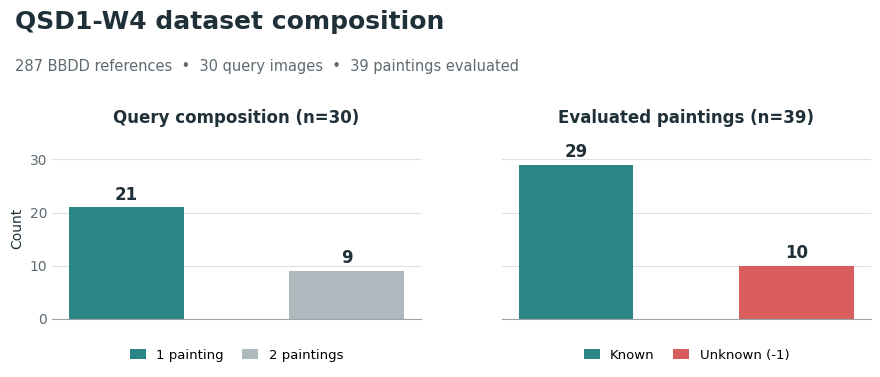

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/e0_qsd1_w4_dataset_summary.png


In [ ]:
#summary of the evaluation population.
TEAL = "#2B8585"
DARK = "#203039"
GREY = "#AEB9BD"
RED = "#D95D5D"

n_queries = len(qsd)
n_paintings = sum(map(len, ground_truth))
n_known = len(known_ids)
n_unknown = unknown_count
n_single = int((inventory["paintings"] == 1).sum())
n_double = int((inventory["paintings"] == 2).sum())

fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.2), sharey=True, facecolor="white")
fig.subplots_adjust(left=0.09, right=0.98, top=0.68, bottom=0.25, wspace=0.22)

panels = [
    (axes[0], [n_single, n_double], ["1 painting", "2 paintings"], [TEAL, GREY], f"Query composition (n={n_queries})"),
    (axes[1], [n_known, n_unknown], ["Known", "Unknown (-1)"], [TEAL, RED], f"Evaluated paintings (n={n_paintings})"),
]
y_max = max(n_single, n_double, n_known, n_unknown) + 5

for axis, values, labels, colors, title in panels:
    positions = np.arange(len(values))
    bars = axis.bar(positions, values, width=0.52, color=colors)
    axis.set_title(title, fontsize=12, fontweight="bold", color=DARK, pad=11)
    axis.set(xticks=[], ylim=(0, y_max))
    axis.grid(axis="y", color="#DCE2E4", linewidth=0.8)
    axis.set_axisbelow(True)
    axis.spines[["top", "right", "left"]].set_visible(False)
    axis.spines["bottom"].set_color("#9AA5AA")
    axis.tick_params(axis="y", length=0, colors="#5E6A70")
    for bar, value in zip(bars, values):
        axis.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.7,
            str(value),
            ha="center",
            va="bottom",
            fontsize=12,
            fontweight="bold",
            color=DARK,
        )
    axis.legend(
        bars,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.10),
        ncol=2,
        frameon=False,
        fontsize=9.5,
        handlelength=1.2,
        columnspacing=1.4,
    )

axes[0].set_ylabel("Count", color=DARK)
fig.text(0.05, 0.94, "QSD1-W4 dataset composition", fontsize=18, fontweight="bold", color=DARK)
fig.text(
    0.05,
    0.84,
    f"{len(bbdd)} BBDD references  •  {n_queries} query images  •  {n_paintings} paintings evaluated",
    fontsize=10.5,
    color="#5E6A70",
)

output_dir = ROOT / "outputs" / "week4"
output_dir.mkdir(parents=True, exist_ok=True)
figure_path = output_dir / "e0_qsd1_w4_dataset_summary.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {figure_path}")

### Dataset finding

Run the three cells above, then record the verified counts and the evaluation implications here before proceeding to E1.

## Baseline painting detection

**Question:** Can the current colour-plus-edge detector recover the correct number of paintings and preserve their left-to-right order?

**Controlled input:** raw QSD1-W4 images. Rotation correction and denoising are held back for the E3 preprocessing ablation.

**Decision evidence:** painting-count outcomes, foreground precision/recall/F1, runtime, and representative success/failure examples.

In [4]:
import time

import cv2

from src.data import load_binary_masks, read_images
from src.evaluation import evaluate_painting_masks
from src.painting_detection import find_paintings

qsd_images = read_images(qsd)
reference_masks = load_binary_masks(qsd.paths)

detected_parts = []
predicted_masks = []
detection_debug = []
detection_times_ms = []

for image in qsd_images:
    started = time.perf_counter()
    parts, debug = find_paintings(image)
    detection_times_ms.append((time.perf_counter() - started) * 1000)
    detected_parts.append(parts)
    predicted_masks.append(debug["combined"])
    detection_debug.append(debug)

mask_summary, detection_rows = evaluate_painting_masks(
    reference_masks,
    predicted_masks,
    detected_parts,
    ground_truth,
    qsd.ids,
)

detection_evaluation = pd.DataFrame(detection_rows)
detection_evaluation["count outcome"] = np.select(
    [
        detection_evaluation["detected paintings"] == detection_evaluation["expected paintings"],
        detection_evaluation["detected paintings"] < detection_evaluation["expected paintings"],
    ],
    ["correct", "under-detected"],
    default="over-detected",
)
detection_evaluation["fallback"] = [bool(debug["fallback"]) for debug in detection_debug]
detection_evaluation["runtime (ms)"] = detection_times_ms

summary_rows = [
    {"averaging": "macro", **mask_summary["macro"]},
    {"averaging": "micro", **mask_summary["micro"], "painting_count_accuracy": np.nan},
]
detection_summary = pd.DataFrame(summary_rows).rename(columns={"f1": "F1"})

display(detection_summary.round(3))
display(
    detection_evaluation[[
        "query",
        "expected paintings",
        "detected paintings",
        "count outcome",
        "precision",
        "recall",
        "F1",
        "fallback",
        "runtime (ms)",
    ]].round(3)
)

,averaging,precision,recall,F1,painting_count_accuracy
0,macro,0.895,0.962,0.915,0.867
1,micro,0.941,0.892,0.916,NaN


,query,expected paintings,detected paintings,count outcome,precision,recall,F1,fallback,runtime (ms)
0,0,1,1,correct,0.967,0.984,0.976,False,839.312
1,1,1,1,correct,0.998,0.895,0.943,False,40.453
2,2,2,2,correct,0.909,1.000,0.952,False,55.010
3,3,1,1,correct,0.916,1.000,0.956,False,35.673
4,4,1,1,correct,0.972,1.000,0.986,False,344.117
5,5,1,1,correct,1.000,0.839,0.913,False,329.972
6,6,2,1,under-detected,0.580,1.000,0.734,False,41.534
7,7,1,1,correct,0.985,0.993,0.989,False,372.073
8,8,1,1,correct,0.791,1.000,0.883,False,41.747
9,9,2,2,correct,0.918,1.000,0.957,False,61.220


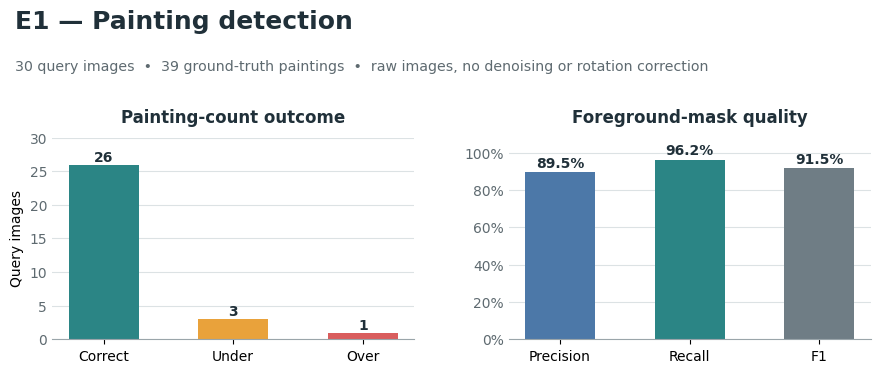

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/e1_painting_detection_summary.png


In [ ]:
#summary: count recovery and mask quality answer different questions.
outcome_order = ["correct", "under-detected", "over-detected"]
outcome_counts = (
    detection_evaluation["count outcome"]
    .value_counts()
    .reindex(outcome_order, fill_value=0)
)
macro_scores = detection_summary.set_index("averaging").loc["macro", ["precision", "recall", "F1"]]

fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.2), facecolor="white")
fig.subplots_adjust(left=0.09, right=0.98, top=0.68, bottom=0.20, wspace=0.26)

count_colors = [TEAL, "#E9A23B", RED]
bars = axes[0].bar(np.arange(3), outcome_counts.values, width=0.54, color=count_colors)
axes[0].set_title("Painting-count outcome", fontsize=12, fontweight="bold", color=DARK, pad=11)
axes[0].set_xticks(np.arange(3), ["Correct", "Under", "Over"])
axes[0].set_ylabel("Query images")
axes[0].set_ylim(0, max(30, int(outcome_counts.max()) + 4))
for bar, value in zip(bars, outcome_counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, value + 0.5, str(int(value)), ha="center", fontweight="bold", color=DARK)

metric_colors = ["#4C78A8", TEAL, "#6F7D85"]
metric_bars = axes[1].bar(np.arange(3), macro_scores.values, width=0.54, color=metric_colors)
axes[1].set_title("Foreground-mask quality", fontsize=12, fontweight="bold", color=DARK, pad=11)
axes[1].set_xticks(np.arange(3), ["Precision", "Recall", "F1"])
axes[1].set_ylim(0, 1.08)
axes[1].set_yticks(np.linspace(0, 1, 6), [f"{value:.0%}" for value in np.linspace(0, 1, 6)])
for bar, value in zip(metric_bars, macro_scores.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, value + 0.025, f"{value:.1%}", ha="center", fontweight="bold", color=DARK)

for axis in axes:
    axis.grid(axis="y", color="#DCE2E4", linewidth=0.8)
    axis.set_axisbelow(True)
    axis.spines[["top", "right", "left"]].set_visible(False)
    axis.spines["bottom"].set_color("#9AA5AA")
    axis.tick_params(axis="y", length=0, colors="#5E6A70")

fig.text(0.05, 0.94, "Painting detection before preprocessing", fontsize=18, fontweight="bold", color=DARK)
fig.text(
    0.05,
    0.84,
    f"{len(qsd)} query images  •  {sum(map(len, ground_truth))} ground-truth paintings  •  raw images, no denoising or rotation correction",
    fontsize=10.2,
    color="#5E6A70",
)

figure_path = output_dir / "e1_painting_detection_summary.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {figure_path}")

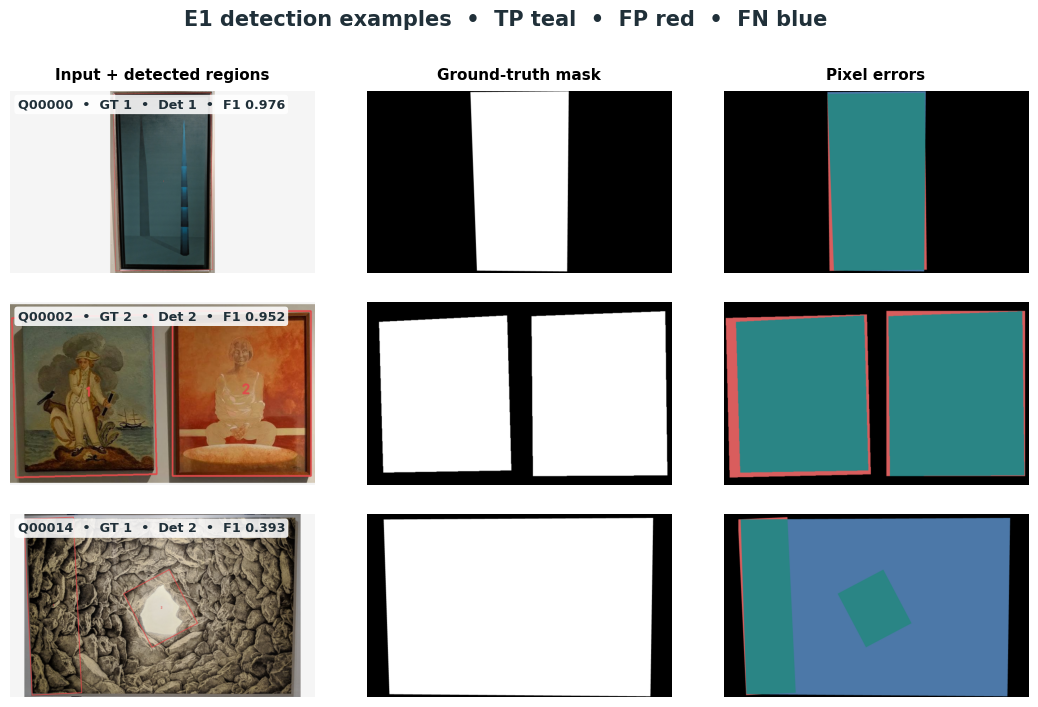

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/e1_painting_detection_examples.png


In [6]:
# Representative evidence: one single-painting success, one two-painting success, and the worst mask.
def first_matching_index(condition):
    matches = detection_evaluation.index[condition].tolist()
    return matches[0] if matches else None

single_success = first_matching_index(
    (detection_evaluation["expected paintings"] == 1)
    & (detection_evaluation["count outcome"] == "correct")
)
double_success = first_matching_index(
    (detection_evaluation["expected paintings"] == 2)
    & (detection_evaluation["count outcome"] == "correct")
)
worst_mask = int(detection_evaluation["F1"].idxmin())
example_indices = [index for index in dict.fromkeys([single_success, double_success, worst_mask]) if index is not None]

def letterbox(value, target_height=420, target_width=700, fill=0):
    height, width = value.shape[:2]
    scale = min(target_width / width, target_height / height)
    resized = cv2.resize(
        value,
        (max(1, round(width * scale)), max(1, round(height * scale))),
        interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR,
    )
    canvas_shape = (target_height, target_width) + (() if value.ndim == 2 else (value.shape[2],))
    canvas = np.full(canvas_shape, fill, dtype=value.dtype)
    y0 = (target_height - resized.shape[0]) // 2
    x0 = (target_width - resized.shape[1]) // 2
    canvas[y0 : y0 + resized.shape[0], x0 : x0 + resized.shape[1]] = resized
    return canvas

fig, axes = plt.subplots(len(example_indices), 3, figsize=(11.0, 2.45 * len(example_indices)), squeeze=False)
fig.subplots_adjust(left=0.035, right=0.99, top=0.86, bottom=0.035, hspace=0.16, wspace=0.06)

for row, query_position in enumerate(example_indices):
    image_rgb = cv2.cvtColor(qsd_images[query_position], cv2.COLOR_BGR2RGB)
    outlined = image_rgb.copy()
    for number, part in enumerate(detected_parts[query_position], start=1):
        polygon = part["polygon"]
        if polygon is None:
            continue
        polygon_int = np.round(polygon).astype(np.int32)
        cv2.polylines(outlined, [polygon_int], True, (224, 74, 74), max(3, round(min(outlined.shape[:2]) / 250)))
        center = np.round(polygon.mean(axis=0)).astype(int)
        cv2.putText(outlined, str(number), tuple(center), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (224, 74, 74), 3, cv2.LINE_AA)

    reference = reference_masks[query_position]
    prediction = predicted_masks[query_position]
    errors = np.zeros((*reference.shape, 3), dtype=np.uint8)
    errors[reference & prediction] = (42, 133, 133)
    errors[~reference & prediction] = (217, 93, 93)
    errors[reference & ~prediction] = (76, 120, 168)

    values = [
        letterbox(outlined, fill=245),
        letterbox(reference.astype(np.uint8) * 255, fill=0),
        letterbox(errors, fill=0),
    ]
    for column, value in enumerate(values):
        if value.ndim == 2:
            axes[row, column].imshow(value, cmap="gray", vmin=0, vmax=255)
        else:
            axes[row, column].imshow(value)
        axes[row, column].axis("off")

    if row == 0:
        for axis, title in zip(axes[row], ["Input + detected regions", "Ground-truth mask", "Pixel errors"]):
            axis.set_title(title, fontsize=11, fontweight="bold", pad=8)

    result = detection_evaluation.loc[query_position]
    axes[row, 0].text(
        0.025,
        0.96,
        f"Q{int(result['query']):05d}  •  GT {int(result['expected paintings'])}  •  Det {int(result['detected paintings'])}  •  F1 {result['F1']:.3f}",
        transform=axes[row, 0].transAxes,
        ha="left",
        va="top",
        fontsize=9.2,
        fontweight="bold",
        color=DARK,
        bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "edgecolor": "none", "alpha": 0.88},
    )

fig.suptitle("Painting detection examples  •  TP teal  •  FP red  •  FN blue", fontsize=15, fontweight="bold", color=DARK, y=0.97)
figure_path = output_dir / "painting_detection_examples.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {figure_path}")

### Baseline detection finding

After running E1, record which errors are caused by painting detection and whether descriptor experiments must also report retrieval on correctly detected paintings.

## Painting detection refinement

**Question:** Can we correct the four painting-count failures without reducing macro mask F1?

**Controlled change:** reject an implausibly thin region only when multiple regions are proposed, and split a single merged proposal only when exactly two distinct rectangular frames are found.

**Selection rule:** maximize painting-count accuracy; retain macro F1 at or above the E1 baseline.

In [7]:
from src.painting_detection import find_paintings_refined

refined_parts = []
refined_masks = []
refined_debug = []
refined_times_ms = []

for image in qsd_images:
    started = time.perf_counter()
    parts, debug = find_paintings_refined(
        image,
        thinness_threshold=0.30,
        frame_min_area=0.08,
    )
    refined_times_ms.append((time.perf_counter() - started) * 1000)
    refined_parts.append(parts)
    refined_masks.append(debug["combined"])
    refined_debug.append(debug)

refined_mask_summary, refined_rows = evaluate_painting_masks(
    reference_masks,
    refined_masks,
    refined_parts,
    ground_truth,
    qsd.ids,
)
refined_evaluation = pd.DataFrame(refined_rows)
refined_evaluation["count outcome"] = np.select(
    [
        refined_evaluation["detected paintings"] == refined_evaluation["expected paintings"],
        refined_evaluation["detected paintings"] < refined_evaluation["expected paintings"],
    ],
    ["correct", "under-detected"],
    default="over-detected",
)

detector_comparison = pd.DataFrame(
    [
        {
            "method": "Baseline detector",
            "correct counts": int((detection_evaluation["count outcome"] == "correct").sum()),
            "count accuracy": mask_summary["macro"]["painting_count_accuracy"],
            "macro precision": mask_summary["macro"]["precision"],
            "macro recall": mask_summary["macro"]["recall"],
            "macro F1": mask_summary["macro"]["F1"],
            "micro F1": mask_summary["micro"]["F1"],
        },
        {
            "method": "Refined detector",
            "correct counts": int((refined_evaluation["count outcome"] == "correct").sum()),
            "count accuracy": refined_mask_summary["macro"]["painting_count_accuracy"],
            "macro precision": refined_mask_summary["macro"]["precision"],
            "macro recall": refined_mask_summary["macro"]["recall"],
            "macro F1": refined_mask_summary["macro"]["F1"],
            "micro F1": refined_mask_summary["micro"]["F1"],
        },
    ]
)

changed_queries = pd.DataFrame(
    [
        {
            "query": int(qsd.ids[index]),
            "baseline count": len(detected_parts[index]),
            "refined count": len(refined_parts[index]),
            "expected count": len(ground_truth[index]),
            "stacked split": bool(refined_debug[index]["split_used"]),
            "thin regions rejected": int(refined_debug[index]["thin_regions_rejected"]),
        }
        for index in range(len(qsd))
        if (
            refined_debug[index]["split_used"]
            or refined_debug[index]["thin_regions_rejected"]
        )
    ]
)

display(detector_comparison.round(3))
display(changed_queries)

,method,correct counts,count accuracy,macro precision,macro recall,macro F1,micro F1
0,E1 baseline,26,0.867,0.895,0.962,0.915,0.916
1,E1b refined,30,1.000,0.919,0.947,0.916,0.905


,query,baseline count,refined count,expected count,stacked split,thin regions rejected
0,6,1,2,2,True,0
1,14,2,1,1,False,1
2,20,1,2,2,True,0
3,28,1,2,2,True,0


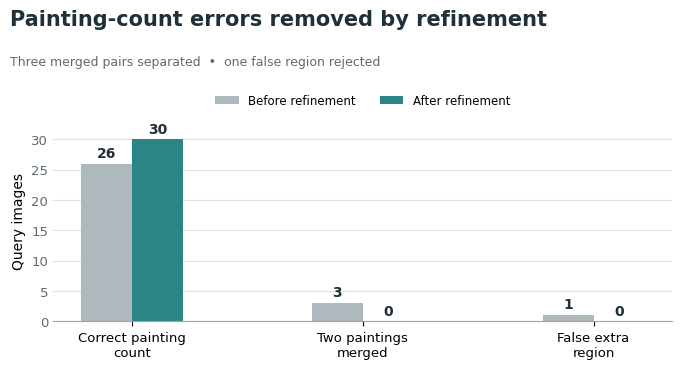

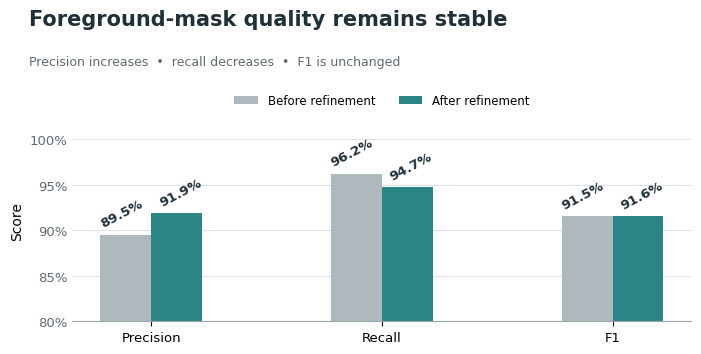

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/painting_count_refinement.png
Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/foreground_mask_quality_refinement.png


In [ ]:
# comparison of the baseline and refined detectors.
outcome_keys = ["correct", "under-detected", "over-detected"]
baseline_counts = [
    int((detection_evaluation["count outcome"] == key).sum())
    for key in outcome_keys
]
refined_counts = [
    int((refined_evaluation["count outcome"] == key).sum())
    for key in outcome_keys
]

BEFORE_COLOR = GREY
AFTER_COLOR = TEAL
BAR_WIDTH = 0.22

# 1) Painting-count outcomes: grouped before/after bars.
count_labels = ["Correct painting\ncount", "Two paintings\nmerged", "False extra\nregion"]
x_count = np.arange(len(count_labels))

fig, axis = plt.subplots(figsize=(7.2, 4.0), facecolor="white")
fig.subplots_adjust(left=0.12, right=0.98, top=0.70, bottom=0.20)
before_bars = axis.bar(
    x_count - BAR_WIDTH / 2, baseline_counts, BAR_WIDTH,
    color=BEFORE_COLOR, label="Before refinement",
)
after_bars = axis.bar(
    x_count + BAR_WIDTH / 2, refined_counts, BAR_WIDTH,
    color=AFTER_COLOR, label="After refinement",
)
for bars in (before_bars, after_bars):
    for bar in bars:
        label_y = bar.get_height() + 0.6 if bar.get_height() > 0 else 0.55
        axis.text(
            bar.get_x() + bar.get_width() / 2, label_y,
            f"{int(bar.get_height())}", ha="center", va="bottom",
            fontweight="bold", color=DARK, fontsize=10,
        )
axis.set_xticks(x_count, count_labels, fontsize=9.5)
axis.set_ylabel("Query images", fontsize=10)
axis.set_ylim(0, 33)
axis.grid(axis="y", color="#DCE2E4", linewidth=0.8)
axis.set_axisbelow(True)
axis.spines[["top", "right", "left"]].set_visible(False)
axis.spines["bottom"].set_color("#9AA5AA")
axis.tick_params(axis="y", length=0, colors="#5E6A70", labelsize=9.5)
fig.text(0.06, 0.94, "Painting-count errors removed by refinement", fontsize=15, fontweight="bold", color=DARK)
fig.text(0.06, 0.84, "Three merged pairs separated  •  one false region rejected", fontsize=9, color="#5E6A70")
axis.legend(loc="upper center", bbox_to_anchor=(0.5, 1.19), frameon=False, ncol=2, fontsize=8.5)
count_figure_path = output_dir / "painting_count_refinement.png"
fig.savefig(count_figure_path, dpi=300, facecolor="white")
plt.show()

# 2) Foreground-mask quality: a separate grouped comparison.
metric_labels = ["Precision", "Recall", "F1"]
metric_keys = ["precision", "recall", "F1"]
baseline_scores = [mask_summary["macro"][key] for key in metric_keys]
refined_scores = [refined_mask_summary["macro"][key] for key in metric_keys]
x_metric = np.arange(len(metric_labels))

fig, axis = plt.subplots(figsize=(7.2, 4.0), facecolor="white")
fig.subplots_adjust(left=0.12, right=0.98, top=0.70, bottom=0.20)
before_bars = axis.bar(
    x_metric - BAR_WIDTH / 2, baseline_scores, BAR_WIDTH,
    color=BEFORE_COLOR, label="Before refinement",
)
after_bars = axis.bar(
    x_metric + BAR_WIDTH / 2, refined_scores, BAR_WIDTH,
    color=AFTER_COLOR, label="After refinement",
)
for bars, horizontal_offset in ((before_bars, -0.018), (after_bars, 0.018)):
    for bar in bars:
        axis.text(
            bar.get_x() + bar.get_width() / 2 + horizontal_offset,
            bar.get_height() + 0.005,
            f"{bar.get_height():.1%}",
            ha="center", va="bottom", rotation=28,
            fontweight="bold", color=DARK, fontsize=9.5,
        )
axis.set_xticks(x_metric, metric_labels, fontsize=9.5)
axis.set_ylim(0.80, 1.02)
score_ticks = np.arange(0.80, 1.01, 0.05)
axis.set_yticks(score_ticks, [f"{value:.0%}" for value in score_ticks])
axis.set_ylabel("Score", fontsize=10)
axis.grid(axis="y", color="#DCE2E4", linewidth=0.8)
axis.set_axisbelow(True)
axis.spines[["top", "right", "left"]].set_visible(False)
axis.spines["bottom"].set_color("#9AA5AA")
axis.tick_params(axis="y", length=0, colors="#5E6A70", labelsize=9.5)
fig.text(0.06, 0.94, "Foreground-mask quality remains stable", fontsize=15, fontweight="bold", color=DARK)
fig.text(0.06, 0.84, "Precision increases  •  recall decreases  •  F1 is unchanged", fontsize=9, color="#5E6A70")
axis.legend(loc="upper center", bbox_to_anchor=(0.5, 1.19), frameon=False, ncol=2, fontsize=8.5)
mask_figure_path = output_dir / "foreground_mask_quality_refinement.png"
fig.savefig(mask_figure_path, dpi=300, facecolor="white")
plt.show()

print(f"Saved: {count_figure_path}")
print(f"Saved: {mask_figure_path}")

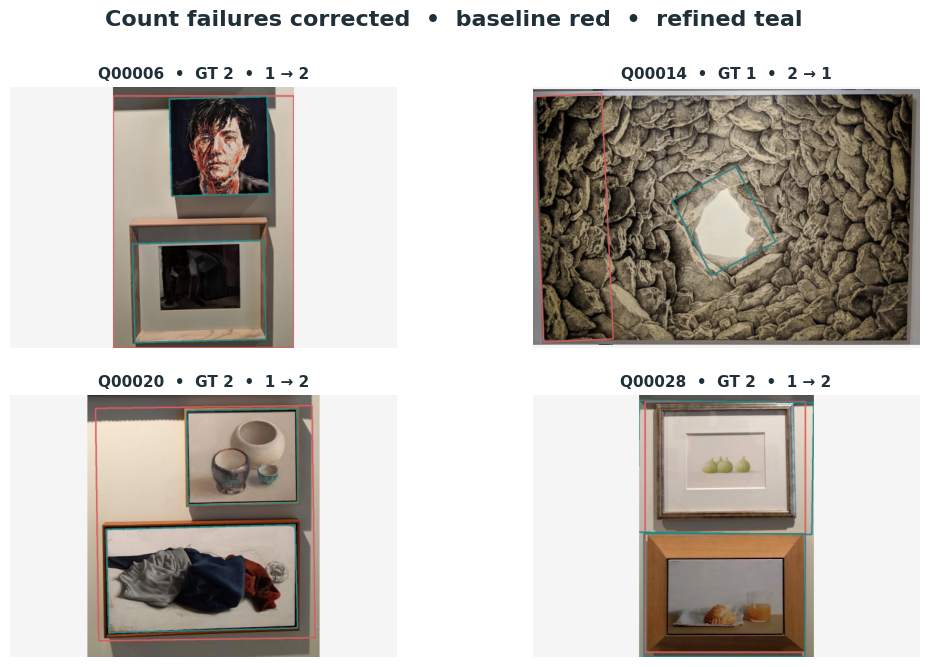

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/e1b_detector_refinement_examples.png


In [9]:
# Visual audit of every query whose painting count changed.
changed_positions = [
    index
    for index, debug in enumerate(refined_debug)
    if debug["split_used"] or debug["thin_regions_rejected"]
]

failure_reason = {
    6: "Two stacked paintings merged",
    14: "Textured strip detected as a painting",
    20: "Two stacked paintings merged",
    28: "Two stacked paintings merged",
}
fig, axes = plt.subplots(2, 2, figsize=(10.6, 7.0), facecolor="white")
fig.subplots_adjust(left=0.035, right=0.985, top=0.85, bottom=0.035, hspace=0.22, wspace=0.08)
for axis, query_position in zip(axes.flat, changed_positions):
    canvas = cv2.cvtColor(qsd_images[query_position], cv2.COLOR_BGR2RGB)
    for part in detected_parts[query_position]:
        if part["polygon"] is not None:
            cv2.polylines(
                canvas, [np.round(part["polygon"]).astype(np.int32)], True,
                (217, 93, 93), max(3, round(min(canvas.shape[:2]) / 180)),
            )
    query_id = int(qsd.ids[query_position])
    axis.imshow(letterbox(canvas, target_height=420, target_width=620, fill=245))
    axis.set_title(
        f"Q{query_id:05d} — {failure_reason[query_id]}",
        fontsize=10.5, fontweight="bold", color=DARK, pad=6,
    )
    axis.axis("off")
fig.suptitle(
    "Why the baseline detector failed",
    fontsize=16, fontweight="bold", color=DARK, y=0.96,
)
failure_path = output_dir / "painting_detection_failures.png"
fig.savefig(failure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {failure_path}")

fig, axes = plt.subplots(2, 2, figsize=(10.6, 7.0), facecolor="white")
fig.subplots_adjust(left=0.035, right=0.985, top=0.85, bottom=0.035, hspace=0.18, wspace=0.08)

for axis, query_position in zip(axes.flat, changed_positions):
    canvas = cv2.cvtColor(qsd_images[query_position], cv2.COLOR_BGR2RGB)

    for part in detected_parts[query_position]:
        if part["polygon"] is not None:
            cv2.polylines(
                canvas,
                [np.round(part["polygon"]).astype(np.int32)],
                True,
                (217, 93, 93),
                max(3, round(min(canvas.shape[:2]) / 220)),
            )

    for part in refined_parts[query_position]:
        if part["polygon"] is not None:
            cv2.polylines(
                canvas,
                [np.round(part["polygon"]).astype(np.int32)],
                True,
                (42, 133, 133),
                max(3, round(min(canvas.shape[:2]) / 180)),
            )

    axis.imshow(letterbox(canvas, target_height=420, target_width=620, fill=245))
    axis.axis("off")
    query_id = int(qsd.ids[query_position])
    expected = len(ground_truth[query_position])
    before = len(detected_parts[query_position])
    after = len(refined_parts[query_position])
    axis.set_title(
        f"Q{query_id:05d}  •  GT {expected}  •  {before} → {after}",
        fontsize=11,
        fontweight="bold",
        color=DARK,
        pad=6,
    )

for axis in axes.flat[len(changed_positions):]:
    axis.axis("off")

fig.suptitle(
    "Refinement corrected all four painting-count errors",
    fontsize=16,
    fontweight="bold",
    color=DARK,
    y=0.96,
)
figure_path = output_dir / "painting_detection_refinement_examples.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {figure_path}")

### Detection-refinement finding

The refined detector corrected all four count failures: Q00006, Q00020 and Q00028 were split into two stacked paintings, while Q00014's narrow false region was rejected. Painting-count accuracy increased from **86.7% to 100%**. Macro precision increased from **89.5% to 91.9%**, recall decreased from **96.2% to 94.7%**, and macro F1 remained stable (**91.5% → 91.6%**).

**Decision:** freeze the refined detector for the next stages. Begin preprocessing experiments only after producing the detected painting crops.

## Raw SIFT retrieval baseline

**Question:** What does the simplest complete local-feature system achieve before denoising, rectification, descriptor alternatives, or unknown rejection?

**Fixed pipeline:** refined painting crops → SIFT (3,000 features) → L2 Lowe ratio test (0.75) → 30-candidate shortlist → RANSAC homography (4 px) → top-10 ranking.

**Primary metric:** known-painting mAP@1. The 10 unknown paintings are retained for the later rejection experiment, not counted as retrieval failures here.

In [10]:
from src.evaluation import map_at_k
from src.local_features import describe_database, describe_parts, retrieve_parts

bbdd_images = read_images(bbdd)

started = time.perf_counter()
sift_query_features = describe_parts(refined_parts, nfeatures=3000)
query_feature_time = time.perf_counter() - started

started = time.perf_counter()
sift_database_features = describe_database(
    bbdd_images,
    bbdd.ids,
    nfeatures=3000,
)
database_feature_time = time.perf_counter() - started

started = time.perf_counter()
sift_baseline_results = retrieve_parts(
    sift_query_features,
    sift_database_features,
    ratio=0.75,
    ransac_threshold=4.0,
    shortlist=30,
    topk=10,
)
retrieval_time = time.perf_counter() - started

assert [len(results) for results in sift_baseline_results] == [
    len(matches) for matches in ground_truth
]

retrieval_rows = []
for query_position, (query_results, matches) in enumerate(
    zip(sift_baseline_results, ground_truth)
):
    for painting_position, (result, ground_truth_id) in enumerate(
        zip(query_results, matches)
    ):
        ranking = result["ranked"]
        rank = (
            ranking.index(int(ground_truth_id)) + 1
            if int(ground_truth_id) in ranking
            else np.nan
        )
        retrieval_rows.append(
            {
                "query position": query_position,
                "query": int(qsd.ids[query_position]),
                "painting position": painting_position,
                "ground truth": int(ground_truth_id),
                "ranked": ranking,
                "rank": rank,
                "rank 1": ranking[0],
                "best inliers": result["best_inliers"],
                "second inliers": result["second_inliers"],
            }
        )

sift_baseline_evaluation = pd.DataFrame(retrieval_rows)
known_sift_results = sift_baseline_evaluation[
    sift_baseline_evaluation["ground truth"] != -1
].copy()
unknown_sift_results = sift_baseline_evaluation[
    sift_baseline_evaluation["ground truth"] == -1
].copy()

known_rankings = known_sift_results["ranked"].tolist()
known_ground_truth = [
    [identifier]
    for identifier in known_sift_results["ground truth"].astype(int)
]
sift_baseline_scores = {
    f"mAP@{k}": map_at_k(known_rankings, known_ground_truth, k)
    for k in (1, 5, 10)
}
sift_baseline_scorecard = pd.DataFrame(
    [
        {
            "known paintings": len(known_sift_results),
            **sift_baseline_scores,
            "query feature time (s)": query_feature_time,
            "database feature time (s)": database_feature_time,
            "retrieval time (s)": retrieval_time,
        }
    ]
)

display(sift_baseline_scorecard.round(3))
display(
    known_sift_results[
        known_sift_results["rank 1"] != known_sift_results["ground truth"]
    ][
        [
            "query",
            "painting position",
            "ground truth",
            "rank 1",
            "rank",
            "best inliers",
            "ranked",
        ]
    ]
)

,known paintings,mAP@1,mAP@5,mAP@10,query feature time (s),database feature time (s),retrieval time (s)
0,29,0.897,0.897,0.897,5.66,56.352,57.997


,query,painting position,ground truth,rank 1,rank,best inliers,ranked
10,8,0,128,25,NaN,0,"[25, 165, 71, 125, 142, 33, 208, 153, 202, 154]"
20,16,0,11,238,NaN,5,"[238, 142, 154, 25, 33, 165, 254, 113, 125, 146]"
36,28,0,47,236,NaN,0,"[236, 142, 157, 107, 211, 165, 238, 240, 212, 3]"


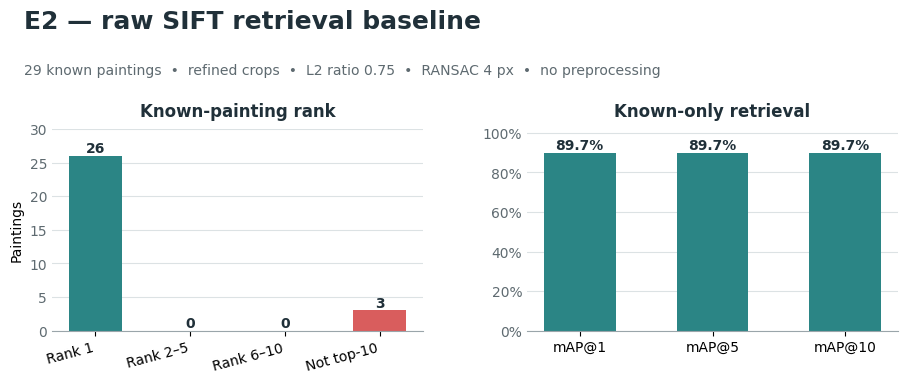

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/e2_sift_baseline_summary.png


In [11]:
# Slide-ready known-painting baseline.
rank_buckets = {
    "Correct at rank 1": int((known_sift_results["rank"] == 1).sum()),
    "Correct at ranks 2–5": int(known_sift_results["rank"].between(2, 5).sum()),
    "Correct at ranks 6–10": int(known_sift_results["rank"].between(6, 10).sum()),
    "Correct outside top 10": int(known_sift_results["rank"].isna().sum()),
}
map_scores = [sift_baseline_scores[f"mAP@{k}"] for k in (1, 5, 10)]

fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.2), facecolor="white")
fig.subplots_adjust(left=0.08, right=0.98, top=0.70, bottom=0.22, wspace=0.28)

x = np.arange(4)
values = list(rank_buckets.values())
bars = axes[0].bar(x, values, width=0.56, color=[TEAL, GREY, GREY, RED])
axes[0].set_title("Position of the correct database painting", fontsize=12, fontweight="bold", color=DARK, pad=9)
axes[0].set_xticks(x, list(rank_buckets), rotation=15, ha="right")
axes[0].set_ylabel("Paintings")
axes[0].set_ylim(0, 30)
for bar, value in zip(bars, values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.5,
        str(value),
        ha="center",
        fontweight="bold",
        color=DARK,
    )

x = np.arange(3)
bars = axes[1].bar(x, map_scores, width=0.54, color=TEAL)
axes[1].set_title("Known-only retrieval", fontsize=12, fontweight="bold", color=DARK, pad=9)
axes[1].set_xticks(x, ["mAP@1", "mAP@5", "mAP@10"])
axes[1].set_ylim(0, 1.02)
axes[1].set_yticks(
    np.linspace(0, 1, 6),
    [f"{value:.0%}" for value in np.linspace(0, 1, 6)],
)
for bar, value in zip(bars, map_scores):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.1%}",
        ha="center",
        fontweight="bold",
        color=DARK,
    )

for axis in axes:
    axis.grid(axis="y", color="#DCE2E4", linewidth=0.8)
    axis.set_axisbelow(True)
    axis.spines[["top", "right", "left"]].set_visible(False)
    axis.spines["bottom"].set_color("#9AA5AA")
    axis.tick_params(axis="y", length=0, colors="#5E6A70")

fig.text(0.05, 0.94, "Raw SIFT retrieval on known paintings", fontsize=18, fontweight="bold", color=DARK)
fig.text(
    0.05,
    0.83,
    "29 known paintings  •  refined crops  •  L2 ratio 0.75  •  RANSAC 4 px  •  no preprocessing",
    fontsize=10.1,
    color="#5E6A70",
)

figure_path = output_dir / "raw_sift_baseline_summary.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {figure_path}")

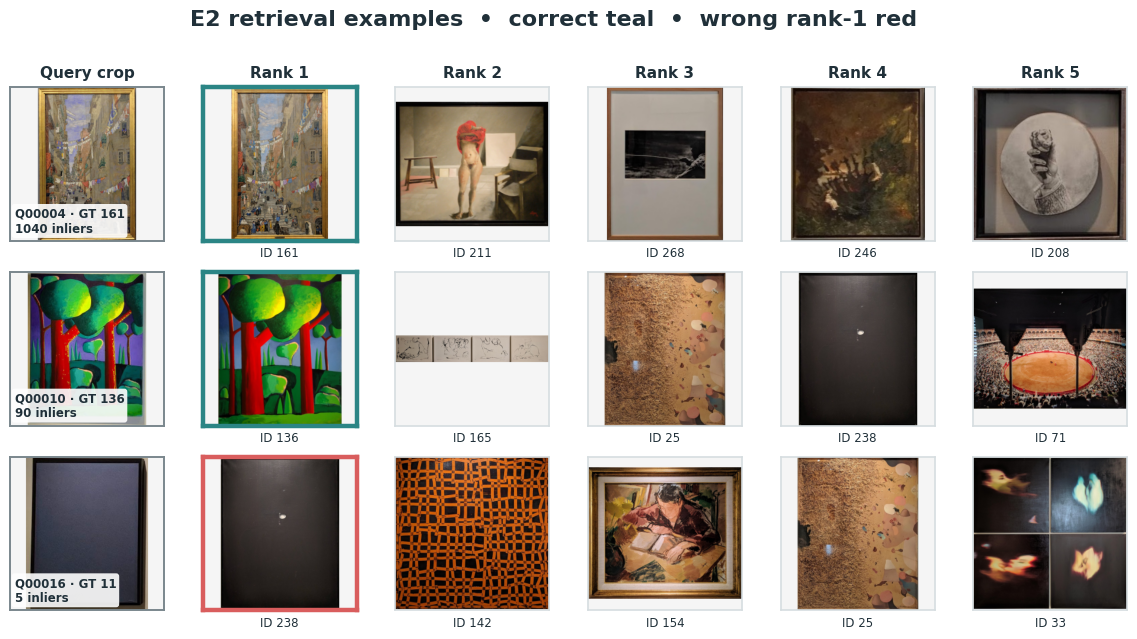

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/e2_sift_top5_examples.png


In [12]:
# Top-5 visual evidence: strongest success, typical success, and strongest failure.
def square_tile(image, size=260, fill=245):
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = rgb.shape[:2]
    scale = min(size / width, size / height)
    resized = cv2.resize(
        rgb,
        (max(1, round(width * scale)), max(1, round(height * scale))),
        interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR,
    )
    canvas = np.full((size, size, 3), fill, dtype=np.uint8)
    y0 = (size - resized.shape[0]) // 2
    x0 = (size - resized.shape[1]) // 2
    canvas[y0 : y0 + resized.shape[0], x0 : x0 + resized.shape[1]] = resized
    return canvas

correct_known = known_sift_results[
    known_sift_results["rank 1"] == known_sift_results["ground truth"]
]
strongest_success = correct_known.loc[correct_known["best inliers"].idxmax()]
median_inliers = float(correct_known["best inliers"].median())
typical_success = correct_known.loc[
    (correct_known["best inliers"] - median_inliers).abs().idxmin()
]
strongest_failure = known_sift_results[
    known_sift_results["rank 1"] != known_sift_results["ground truth"]
].sort_values("best inliers", ascending=False).iloc[0]
retrieval_examples = [strongest_success, typical_success, strongest_failure]

bbdd_image_by_id = {
    int(identifier): image
    for identifier, image in zip(bbdd.ids, bbdd_images)
}

fig, axes = plt.subplots(3, 6, figsize=(12.0, 6.5), facecolor="white")
fig.subplots_adjust(
    left=0.035,
    right=0.99,
    top=0.84,
    bottom=0.035,
    hspace=0.20,
    wspace=0.055,
)
for column, title in enumerate(
    ["Query crop", "Rank 1", "Rank 2", "Rank 3", "Rank 4", "Rank 5"]
):
    axes[0, column].set_title(
        title,
        fontsize=11,
        fontweight="bold",
        color=DARK,
        pad=7,
    )

for row, record in enumerate(retrieval_examples):
    query_position = int(record["query position"])
    painting_position = int(record["painting position"])
    query_crop = refined_parts[query_position][painting_position]["crop"]
    ranking = record["ranked"][:5]
    images = [query_crop] + [bbdd_image_by_id[int(identifier)] for identifier in ranking]
    identifiers = [None] + ranking

    for column, (axis, image, identifier) in enumerate(
        zip(axes[row], images, identifiers)
    ):
        axis.imshow(square_tile(image))
        axis.set_xticks([])
        axis.set_yticks([])

        if column == 0:
            axis.text(
                0.03,
                0.04,
                (
                    f"Q{int(record['query']):05d} · GT {int(record['ground truth'])}\n"
                    f"{int(record['best inliers'])} inliers"
                ),
                transform=axis.transAxes,
                ha="left",
                va="bottom",
                fontsize=8.5,
                fontweight="bold",
                color=DARK,
                bbox={
                    "boxstyle": "round,pad=0.25",
                    "facecolor": "white",
                    "edgecolor": "none",
                    "alpha": 0.90,
                },
            )
            border, border_width = "#7A878D", 1.4
        else:
            identifier = int(identifier)
            axis.set_xlabel(f"ID {identifier}", fontsize=8.5, color=DARK, labelpad=4)
            correct_match = identifier == int(record["ground truth"])
            wrong_top1 = column == 1 and not correct_match
            border = TEAL if correct_match else RED if wrong_top1 else "#D6DDE0"
            border_width = 3.2 if (correct_match or wrong_top1) else 1.2

        for spine in axis.spines.values():
            spine.set_color(border)
            spine.set_linewidth(border_width)

fig.suptitle(
    "Representative top-5 retrievals  •  correct teal  •  wrong rank-1 red",
    fontsize=16,
    fontweight="bold",
    color=DARK,
    y=0.96,
)
figure_path = output_dir / "raw_sift_top5_examples.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {figure_path}")

### Raw retrieval finding

The raw SIFT baseline retrieves **26 of 29 known paintings at rank 1**: **mAP@1 = mAP@5 = mAP@10 = 0.897**. The three failures—Q00008, Q00016 and the first painting in Q00028—are not recovered in the top 10.

All ten unknown painting instances (ground truth `-1`) produced zero best-match RANSAC inliers in this run. This is promising separation evidence, but the rejection threshold is tested separately.

**Decision:** retain this configuration as the frozen retrieval baseline for the preprocessing ablation.

## Preprocessing ablation

In [13]:
# Purpose: change only crop preprocessing while keeping detections and SIFT matching frozen.
from src.retrieval import order_box_points

DENOISE_PARAMETERS = {
    "pixel_difference": 40,
    "isolated_percent_threshold": 0.25,
    "kernel_size": 3,
}


def isolated_difference_map(gray):
    """Minimum absolute difference from each pixel to its eight neighbours."""
    padded = cv2.copyMakeBorder(gray, 1, 1, 1, 1, cv2.BORDER_REFLECT)
    height, width = gray.shape
    result = None
    for delta_y in (-1, 0, 1):
        for delta_x in (-1, 0, 1):
            if delta_x == 0 and delta_y == 0:
                continue
            neighbour = padded[
                1 + delta_y : 1 + delta_y + height,
                1 + delta_x : 1 + delta_x + width,
            ]
            difference = cv2.absdiff(gray, neighbour)
            result = difference if result is None else np.minimum(result, difference)
    return result


def conditional_median_filter(image, parameters=DENOISE_PARAMETERS):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    isolated_percent = 100 * np.mean(
        isolated_difference_map(gray) > parameters["pixel_difference"]
    )
    apply_filter = bool(
        isolated_percent > parameters["isolated_percent_threshold"]
    )
    filtered = (
        cv2.medianBlur(image, parameters["kernel_size"])
        if apply_filter
        else image.copy()
    )
    return filtered, {
        "denoised": apply_filter,
        "isolated pixels (%)": float(isolated_percent),
    }


def rectify_detected_painting(image, polygon):
    """Warp a detected rotated rectangle into an upright rectangular crop."""
    if polygon is None:
        return image.copy()
    source = order_box_points(polygon)
    top_left, top_right, bottom_right, bottom_left = source
    width = max(
        int(round(np.linalg.norm(top_right - top_left))),
        int(round(np.linalg.norm(bottom_right - bottom_left))),
        2,
    )
    height = max(
        int(round(np.linalg.norm(bottom_left - top_left))),
        int(round(np.linalg.norm(bottom_right - top_right))),
        2,
    )
    destination = np.array(
        [[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]],
        dtype=np.float32,
    )
    transform = cv2.getPerspectiveTransform(source, destination)
    return cv2.warpPerspective(
        image, transform, (width, height),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REPLICATE,
    )


def prepare_detected_parts(images, parts_per_query, *, denoise=False, rectify=False):
    """Reuse frozen detections and replace only the pixels passed to SIFT."""
    prepared_queries = []
    audit_rows = []
    for query_position, (image, parts) in enumerate(zip(images, parts_per_query)):
        if denoise:
            working_image, noise_info = conditional_median_filter(image)
        else:
            working_image = image
            noise_info = {"denoised": False, "isolated pixels (%)": np.nan}

        prepared_parts = []
        rectified_count = 0
        for part in parts:
            polygon = part["polygon"]
            if rectify and polygon is not None:
                crop = rectify_detected_painting(working_image, polygon)
                mask = None
                rectified_count += 1
            else:
                x0, y0, x1, y1 = part["bbox"]
                crop = working_image[y0:y1, x0:x1].copy()
                mask = part["mask"]
            prepared_parts.append({**part, "crop": crop, "mask": mask})

        prepared_queries.append(prepared_parts)
        audit_rows.append({
            "query": int(qsd.ids[query_position]),
            "paintings": len(prepared_parts),
            "denoised": noise_info["denoised"],
            "isolated pixels (%)": noise_info["isolated pixels (%)"],
            "rectified paintings": rectified_count,
        })
    return prepared_queries, pd.DataFrame(audit_rows)

In [14]:
# Build one-change-at-a-time variants from the same refined detections.
preprocessing_specifications = {
    "Raw crops": {"denoise": False, "rectify": False},
    "Conditional median 3×3": {"denoise": True, "rectify": False},
    "Geometric rectification": {"denoise": False, "rectify": True},
    "Rectification + median": {"denoise": True, "rectify": True},
}

preprocessing_parts = {}
preprocessing_audits = {}
for variant_name, parameters in preprocessing_specifications.items():
    parts, audit = prepare_detected_parts(
        qsd_images, refined_parts, **parameters
    )
    preprocessing_parts[variant_name] = parts
    preprocessing_audits[variant_name] = audit

preprocessing_audit_summary = pd.DataFrame([
    {
        "variant": variant_name,
        "queries": len(audit),
        "denoised queries": int(audit["denoised"].sum()),
        "rectified paintings": int(audit["rectified paintings"].sum()),
    }
    for variant_name, audit in preprocessing_audits.items()
])
display(preprocessing_audit_summary)

,variant,queries,denoised queries,rectified paintings
0,Raw crops,30,0,0
1,Conditional median 3×3,30,9,0
2,Geometric rectification,30,0,37
3,Rectification + median,30,9,37


In [15]:
# Evaluate every preprocessing variant with the frozen SIFT matcher.
def evaluate_preprocessing_variant(variant_name, prepared_parts):
    started = time.perf_counter()
    query_features = describe_parts(prepared_parts, nfeatures=3000)
    feature_time = time.perf_counter() - started

    started = time.perf_counter()
    results = retrieve_parts(
        query_features,
        sift_database_features,
        ratio=0.75,
        ransac_threshold=4.0,
        shortlist=30,
        topk=10,
    )
    retrieval_time = time.perf_counter() - started

    rows = []
    for query_position, (query_results, matches) in enumerate(zip(results, ground_truth)):
        for painting_position, (result, ground_truth_id) in enumerate(zip(query_results, matches)):
            ranking = result["ranked"]
            known = int(ground_truth_id) != -1
            rank = (
                ranking.index(int(ground_truth_id)) + 1
                if known and int(ground_truth_id) in ranking
                else np.nan
            )
            rows.append({
                "variant": variant_name,
                "query position": query_position,
                "query": int(qsd.ids[query_position]),
                "painting position": painting_position,
                "ground truth": int(ground_truth_id),
                "rank 1": int(ranking[0]),
                "rank": rank,
                "ranked": ranking,
                "best inliers": int(result["best_inliers"]),
                "correct at rank 1": bool(known and ranking[0] == int(ground_truth_id)),
            })

    details = pd.DataFrame(rows)
    known_details = details[details["ground truth"] != -1].copy()
    rankings = known_details["ranked"].tolist()
    references = [[identifier] for identifier in known_details["ground truth"].astype(int)]
    score = {
        "variant": variant_name,
        "known paintings": len(known_details),
        "correct at rank 1": int(known_details["correct at rank 1"].sum()),
        **{f"mAP@{k}": map_at_k(rankings, references, k) for k in (1, 5, 10)},
        "feature time (s)": feature_time,
        "retrieval time (s)": retrieval_time,
        "total time (s)": feature_time + retrieval_time,
    }
    return score, details, results


preprocessing_scores = []
preprocessing_details = {}
preprocessing_results = {}
for variant_name, prepared_parts in preprocessing_parts.items():
    score, details, results = evaluate_preprocessing_variant(
        variant_name, prepared_parts
    )
    preprocessing_scores.append(score)
    preprocessing_details[variant_name] = details
    preprocessing_results[variant_name] = results

preprocessing_scorecard = pd.DataFrame(preprocessing_scores)
display(preprocessing_scorecard.round(3))

,variant,known paintings,correct at rank 1,mAP@1,mAP@5,mAP@10,feature time (s),retrieval time (s),total time (s)
0,Raw crops,29,26,0.897,0.897,0.897,5.826,59.235,65.062
1,Conditional median 3×3,29,26,0.897,0.897,0.897,5.615,56.683,62.298
2,Geometric rectification,29,27,0.931,0.931,0.931,5.167,56.909,62.076
3,Rectification + median,29,27,0.931,0.931,0.931,5.373,54.700,60.073


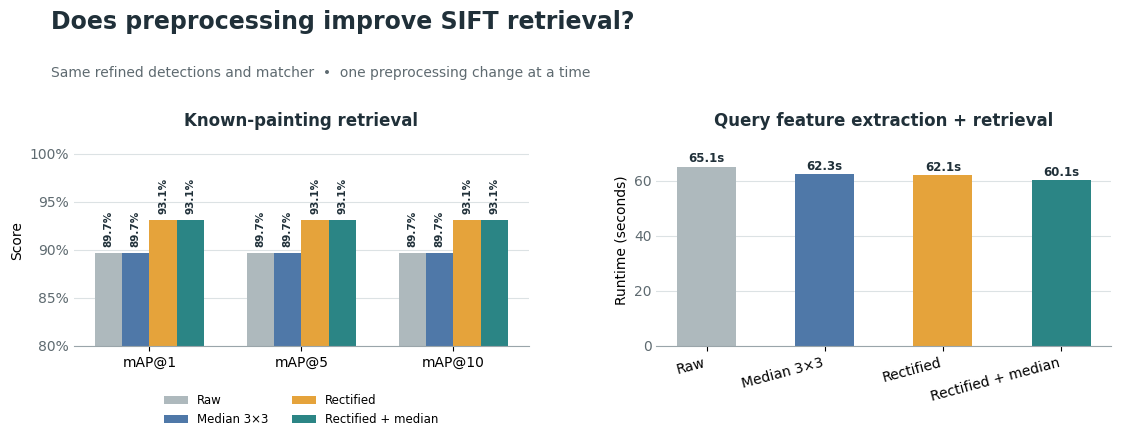

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/preprocessing_ablation_summary.png


In [16]:
# Slide-ready comparison: retrieval quality and total query-side runtime.
variant_order = list(preprocessing_specifications)
short_labels = ["Raw", "Median 3×3", "Rectified", "Rectified + median"]
variant_colors = [GREY, "#4F78A8", "#E5A33B", TEAL]
metric_names = ["mAP@1", "mAP@5", "mAP@10"]
ordered_scores = preprocessing_scorecard.set_index("variant").loc[variant_order]

fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.4), facecolor="white")
fig.subplots_adjust(left=0.07, right=0.98, top=0.70, bottom=0.22, wspace=0.28)

x = np.arange(len(metric_names))
bar_width = 0.18
all_metric_values = ordered_scores[metric_names].to_numpy()
lower_limit = max(0, np.floor((all_metric_values.min() - 0.05) * 20) / 20)
for variant_position, (label, color) in enumerate(zip(short_labels, variant_colors)):
    values = ordered_scores.iloc[variant_position][metric_names].to_numpy(dtype=float)
    offset = (variant_position - 1.5) * bar_width
    bars = axes[0].bar(x + offset, values, bar_width, label=label, color=color)
    for bar, value in zip(bars, values):
        axes[0].text(
            bar.get_x() + bar.get_width() / 2, value + 0.006, f"{value:.1%}",
            ha="center", va="bottom", rotation=90, fontsize=7.5,
            fontweight="bold", color=DARK,
        )
axes[0].set_title("Known-painting retrieval", fontsize=12, fontweight="bold", color=DARK, pad=42)
axes[0].set_xticks(x, metric_names)
axes[0].set_ylim(lower_limit, 1.04)
axes[0].set_yticks(
    np.linspace(lower_limit, 1.0, 5),
    [f"{value:.0%}" for value in np.linspace(lower_limit, 1.0, 5)],
)
axes[0].set_ylabel("Score")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False, fontsize=8.5)

runtime_values = ordered_scores["total time (s)"].to_numpy(dtype=float)
bars = axes[1].bar(np.arange(len(short_labels)), runtime_values, width=0.50, color=variant_colors)
axes[1].set_title("Query feature extraction + retrieval", fontsize=12, fontweight="bold", color=DARK)
axes[1].set_xticks(np.arange(len(short_labels)), short_labels, rotation=15, ha="right")
axes[1].set_ylabel("Runtime (seconds)")
axes[1].set_ylim(0, runtime_values.max() * 1.18)
for bar, value in zip(bars, runtime_values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2, value + runtime_values.max() * 0.025,
        f"{value:.1f}s", ha="center", fontweight="bold", color=DARK, fontsize=8.5,
    )

for axis in axes:
    axis.grid(axis="y", color="#DCE2E4", linewidth=0.8)
    axis.set_axisbelow(True)
    axis.spines[["top", "right", "left"]].set_visible(False)
    axis.spines["bottom"].set_color("#9AA5AA")
    axis.tick_params(axis="y", length=0, colors="#5E6A70")

fig.text(0.05, 0.94, "Does preprocessing improve SIFT retrieval?", fontsize=17, fontweight="bold", color=DARK)
fig.text(0.05, 0.83, "Same refined detections and matcher  •  one preprocessing change at a time", fontsize=10, color="#5E6A70")
figure_path = output_dir / "preprocessing_ablation_summary.png"
fig.savefig(figure_path, dpi=300, facecolor="white")
plt.show()
print(f"Saved: {figure_path}")

query,painting,expected BBDD ID,raw prediction,raw inliers,rectified prediction,rectified inliers,outcome
Q00028,1,47,236,0,47,15,recovered by rectification


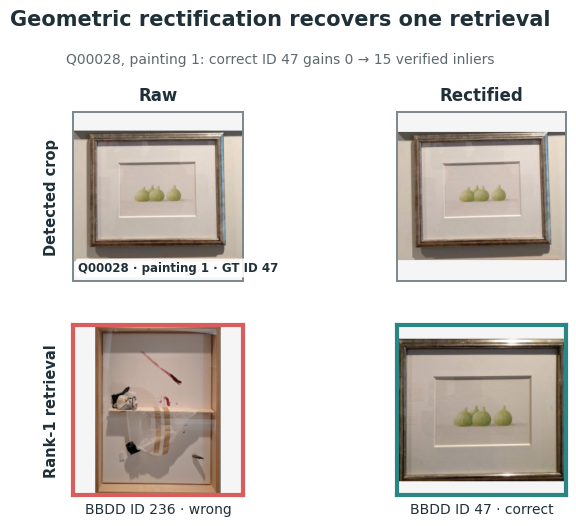

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/rectification_changed_retrievals.png


In [20]:
# Identify and visualize every known painting whose rank-1 outcome changed.
raw_known = preprocessing_details["Raw crops"].query("`ground truth` != -1").copy()
rectified_known = preprocessing_details["Geometric rectification"].query("`ground truth` != -1").copy()
comparison_keys = ["query position", "query", "painting position", "ground truth"]
rectification_comparison = raw_known.merge(
    rectified_known,
    on=comparison_keys,
    suffixes=(" raw", " rectified"),
)
changed_retrievals = rectification_comparison[
    rectification_comparison["correct at rank 1 raw"]
    != rectification_comparison["correct at rank 1 rectified"]
].copy()
changed_retrievals["outcome"] = np.where(
    changed_retrievals["correct at rank 1 rectified"],
    "recovered by rectification",
    "lost after rectification",
)
change_table = changed_retrievals[[
    "query", "painting position", "ground truth",
    "rank 1 raw", "best inliers raw",
    "rank 1 rectified", "best inliers rectified", "outcome",
]].copy()
change_table["query"] = change_table["query"].map(lambda value: f"Q{int(value):05d}")
change_table["painting position"] += 1
change_table = change_table.rename(columns={
    "painting position": "painting",
    "ground truth": "expected BBDD ID",
    "rank 1 raw": "raw prediction",
    "best inliers raw": "raw inliers",
    "rank 1 rectified": "rectified prediction",
    "best inliers rectified": "rectified inliers",
})
display(change_table.style.hide(axis="index"))

if len(changed_retrievals):
    fig, axes = plt.subplots(
        2 * len(changed_retrievals), 2,
        figsize=(7.2, 5.4 * len(changed_retrievals)),
        squeeze=False, facecolor="white",
    )
    fig.subplots_adjust(
        left=0.13, right=0.98, top=0.78, bottom=0.07,
        hspace=0.26, wspace=0.12,
    )
    column_titles = ["Raw", "Rectified"]
    for column, title in enumerate(column_titles):
        axes[0, column].set_title(
            title, fontsize=12, fontweight="bold", color=DARK, pad=8
        )

    for row_position, (_, record) in enumerate(changed_retrievals.iterrows()):
        query_position = int(record["query position"])
        query_id = int(record["query"])
        painting_position = int(record["painting position"])
        ground_truth_id = int(record["ground truth"])
        raw_rank_1 = int(record["rank 1 raw"])
        rectified_rank_1 = int(record["rank 1 rectified"])

        crop_row = 2 * row_position
        retrieval_row = crop_row + 1
        crop_images = [
            preprocessing_parts["Raw crops"][query_position][painting_position]["crop"],
            preprocessing_parts["Geometric rectification"][query_position][painting_position]["crop"],
        ]
        retrieval_images = [bbdd_image_by_id[raw_rank_1], bbdd_image_by_id[rectified_rank_1]]
        retrieval_ids = [raw_rank_1, rectified_rank_1]

        for column, image in enumerate(crop_images):
            axis = axes[crop_row, column]
            axis.imshow(square_tile(image))
            axis.set_xticks([])
            axis.set_yticks([])
            for spine in axis.spines.values():
                spine.set_color("#7A878D")
                spine.set_linewidth(1.4)

        for column, (image, identifier) in enumerate(zip(retrieval_images, retrieval_ids)):
            axis = axes[retrieval_row, column]
            axis.imshow(square_tile(image))
            axis.set_xticks([])
            axis.set_yticks([])
            correct = identifier == ground_truth_id
            border = TEAL if correct else RED
            symbol = "correct" if correct else "wrong"
            axis.set_xlabel(
                f"BBDD ID {identifier} · {symbol}",
                fontsize=10, color=DARK, labelpad=5,
            )
            for spine in axis.spines.values():
                spine.set_color(border)
                spine.set_linewidth(3.0)

        axes[crop_row, 0].set_ylabel(
            "Detected crop", fontsize=10.5, fontweight="bold", color=DARK, labelpad=10
        )
        axes[retrieval_row, 0].set_ylabel(
            "Rank-1 retrieval", fontsize=10.5, fontweight="bold", color=DARK, labelpad=10
        )

        axes[crop_row, 0].text(
            0.03, 0.04,
            f"Q{query_id:05d} · painting {painting_position + 1} · GT ID {ground_truth_id}",
            transform=axes[crop_row, 0].transAxes,
            ha="left", va="bottom", fontsize=8.5, fontweight="bold", color=DARK,
            bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "edgecolor": "none", "alpha": 0.9},
        )

    first_change = changed_retrievals.iloc[0]
    fig.suptitle(
        "Geometric rectification recovers one retrieval",
        fontsize=15, fontweight="bold", color=DARK, y=0.97,
    )
    fig.text(
        0.5, 0.87,
        (
            f"Q{int(first_change['query']):05d}, painting "
            f"{int(first_change['painting position']) + 1}: correct ID "
            f"{int(first_change['ground truth'])} gains "
            f"{int(first_change['best inliers raw'])} → "
            f"{int(first_change['best inliers rectified'])} verified inliers"
        ),
        ha="center", fontsize=10, color="#5E6A70",
    )
    figure_path = output_dir / "rectification_changed_retrievals.png"
    fig.savefig(figure_path, dpi=300, facecolor="white")
    plt.show()
    print(f"Saved: {figure_path}")
else:
    print("No known painting changed its rank-1 correctness after rectification.")

## Local-descriptor comparison

- Compare the teammate-consistent set: **SIFT, ORB and COLOR-SIFT**.
- Freeze refined detections, geometric rectification, 3,000-keypoint cap, Lowe ratio 0.75, RANSAC 4 px and top-10 retrieval.
- Measure retrieval accuracy, query inference time, feature footprint and geometrically verified match quality.

In [21]:
# Reuse the descriptor implementations already tested in the team notebook.
import os

from joblib import Parallel, delayed

from src.local_features import ransac_inliers


class ColorSIFTDetector:
    uses_colour = True

    def __init__(self, nfeatures=3000):
        self.sift = cv2.SIFT_create(nfeatures=nfeatures)

    @staticmethod
    def opponent_channels(image_bgr):
        b, g, r = [channel.astype(np.float32) for channel in cv2.split(image_bgr)]
        channels = [
            ((r - g) / np.sqrt(2), -255 / np.sqrt(2), 255 / np.sqrt(2)),
            ((r + g - 2 * b) / np.sqrt(6), -510 / np.sqrt(6), 510 / np.sqrt(6)),
            ((r + g + b) / np.sqrt(3), 0, 765 / np.sqrt(3)),
        ]
        return [
            np.clip((channel - low) / (high - low) * 255, 0, 255).astype(np.uint8)
            for channel, low, high in channels
        ]

    def detectAndCompute(self, image, mask=None):
        if image.ndim == 2:
            image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
        keypoints = list(
            self.sift.detect(cv2.cvtColor(image, cv2.COLOR_BGR2GRAY), mask)
        )
        if not keypoints:
            return [], None
        channel_descriptors = [
            self.sift.compute(channel, keypoints)[1]
            for channel in self.opponent_channels(image)
        ]
        if any(descriptors is None for descriptors in channel_descriptors):
            return [], None
        return keypoints, np.hstack(channel_descriptors)


DESCRIPTOR_SPECIFICATIONS = {
    "SIFT": {"norm": cv2.NORM_L2, "format": "128 × float32"},
    "ORB": {"norm": cv2.NORM_HAMMING, "format": "256 bits"},
    "COLOR-SIFT": {"norm": cv2.NORM_L2, "format": "384 × float32"},
}
DESCRIPTOR_METHODS = list(DESCRIPTOR_SPECIFICATIONS)
N_FEATURES = 3000
RATIO_THRESHOLD = 0.75
RANSAC_THRESHOLD = 4.0
N_WORKERS = min(6, max(1, (os.cpu_count() or 2) - 1))


def create_local_descriptor(method, nfeatures=N_FEATURES):
    if method == "SIFT":
        return cv2.SIFT_create(nfeatures=nfeatures), False
    if method == "ORB":
        return cv2.ORB_create(nfeatures=nfeatures), False
    if method == "COLOR-SIFT":
        return ColorSIFTDetector(nfeatures=nfeatures), True
    raise ValueError(f"Unsupported descriptor: {method}")


def extract_local_feature_record(image, method, mask=None, nfeatures=N_FEATURES):
    cv2.setNumThreads(1)
    detector, uses_colour = create_local_descriptor(method, nfeatures)
    detector_input = (
        image
        if uses_colour
        else cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    )
    started = time.perf_counter()
    keypoints, descriptors = detector.detectAndCompute(detector_input, mask)
    elapsed_ms = (time.perf_counter() - started) * 1000
    points = np.asarray(
        [keypoint.pt for keypoint in keypoints], dtype=np.float32
    ).reshape(-1, 2)
    return {
        "points": points,
        "descriptors": descriptors,
        "keypoints": len(points),
        "extraction ms": elapsed_ms,
    }


def extract_path_feature_record(path, method, nfeatures=N_FEATURES):
    image = cv2.imread(str(path))
    if image is None:
        raise FileNotFoundError(path)
    return extract_local_feature_record(image, method, None, nfeatures)


def accepted_descriptor_matches(query_descriptors, reference_descriptors, norm, ratio=RATIO_THRESHOLD):
    if (
        query_descriptors is None
        or reference_descriptors is None
        or len(query_descriptors) < 2
        or len(reference_descriptors) < 2
    ):
        return np.zeros(0, dtype=int), np.zeros(0, dtype=int)
    pairs = cv2.BFMatcher(norm).knnMatch(
        query_descriptors, reference_descriptors, k=2
    )
    accepted = [
        pair[0]
        for pair in pairs
        if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance
    ]
    return (
        np.asarray([match.queryIdx for match in accepted], dtype=int),
        np.asarray([match.trainIdx for match in accepted], dtype=int),
    )


def rank_descriptor_database(query_feature, database_features, norm, topk=10, shortlist=30):
    matches = {
        identifier: accepted_descriptor_matches(
            query_feature["descriptors"], reference["descriptors"], norm
        )
        for identifier, reference in database_features.items()
    }
    candidates = sorted(
        matches, key=lambda identifier: len(matches[identifier][0]), reverse=True
    )[:shortlist]
    inliers = {
        identifier: ransac_inliers(
            query_feature["points"],
            database_features[identifier]["points"],
            *matches[identifier],
            threshold=RANSAC_THRESHOLD,
        )
        for identifier in candidates
    }
    ranking = sorted(
        database_features,
        key=lambda identifier: (
            inliers.get(identifier, -1), len(matches[identifier][0])
        ),
        reverse=True,
    )[:topk]
    scores = sorted(inliers.values(), reverse=True)
    return {
        "ranked": [int(identifier) for identifier in ranking],
        "best inliers": int(scores[0]) if scores else 0,
        "second inliers": int(scores[1]) if len(scores) > 1 else 0,
    }


def descriptor_bytes(feature):
    descriptors = feature["descriptors"]
    return 0 if descriptors is None else int(descriptors.nbytes)


In [22]:
# Run methods sequentially for fair timing; parallelize independent images and share BBDD features across matching threads.
rectified_parts = preprocessing_parts["Geometric rectification"]
cv2.setNumThreads(1)


def evaluate_descriptor_method(method):
    specification = DESCRIPTOR_SPECIFICATIONS[method]
    norm = specification["norm"]

    flat_query_parts = [part for query_parts in rectified_parts for part in query_parts]
    started = time.perf_counter()
    query_features_flat = Parallel(n_jobs=N_WORKERS, backend="loky")(
        delayed(extract_local_feature_record)(
            part["crop"], method, part["mask"], N_FEATURES
        )
        for part in flat_query_parts
    )
    query_feature_wall_ms = (time.perf_counter() - started) * 1000

    feature_iterator = iter(query_features_flat)
    query_features = [
        [next(feature_iterator) for _ in query_parts]
        for query_parts in rectified_parts
    ]

    database_records = Parallel(n_jobs=N_WORKERS, backend="loky")(
        delayed(extract_path_feature_record)(path, method, N_FEATURES)
        for path in bbdd.paths
    )
    database_features = {
        int(identifier): feature
        for identifier, feature in zip(bbdd.ids, database_records)
    }

    retrieval_tasks = [
        (query_position, painting_position, feature, int(ground_truth_id))
        for query_position, (features, references) in enumerate(
            zip(query_features, ground_truth)
        )
        for painting_position, (feature, ground_truth_id) in enumerate(
            zip(features, references)
        )
    ]

    def evaluate_painting(query_position, painting_position, feature, ground_truth_id):
        started = time.perf_counter()
        result = rank_descriptor_database(feature, database_features, norm)
        retrieval_ms = (time.perf_counter() - started) * 1000
        ranking = result["ranked"]
        known = ground_truth_id != -1
        rank = (
            ranking.index(ground_truth_id) + 1
            if known and ground_truth_id in ranking
            else np.nan
        )

        tentative_matches = np.nan
        verified_inliers = np.nan
        inlier_ratio = np.nan
        if known:
            query_indices, reference_indices = accepted_descriptor_matches(
                feature["descriptors"],
                database_features[ground_truth_id]["descriptors"],
                norm,
            )
            tentative_matches = len(query_indices)
            verified_inliers = ransac_inliers(
                feature["points"],
                database_features[ground_truth_id]["points"],
                query_indices, reference_indices,
                threshold=RANSAC_THRESHOLD,
            )
            inlier_ratio = verified_inliers / max(tentative_matches, 1)

        return {
            "method": method,
            "query position": query_position,
            "query": int(qsd.ids[query_position]),
            "painting position": painting_position,
            "ground truth": ground_truth_id,
            "ranked": ranking,
            "rank": rank,
            "rank 1": int(ranking[0]),
            "best inliers": result["best inliers"],
            "retrieval ms": retrieval_ms,
            "tentative matches to GT": tentative_matches,
            "verified inliers to GT": verified_inliers,
            "GT inlier ratio": inlier_ratio,
        }

    started = time.perf_counter()
    rows = Parallel(n_jobs=N_WORKERS, backend="threading")(
        delayed(evaluate_painting)(*task) for task in retrieval_tasks
    )
    retrieval_wall_ms = (time.perf_counter() - started) * 1000
    details = pd.DataFrame(rows)
    known_details = details[details["ground truth"] != -1].copy()
    rankings = known_details["ranked"].tolist()
    references = [[identifier] for identifier in known_details["ground truth"].astype(int)]

    valid_descriptors = [
        feature["descriptors"]
        for feature in query_features_flat
        if feature["descriptors"] is not None and len(feature["descriptors"])
    ]
    bytes_per_keypoint = np.median([
        descriptors.nbytes / len(descriptors)
        for descriptors in valid_descriptors
    ])
    score = {
        "method": method,
        "descriptor format": specification["format"],
        "known paintings": len(known_details),
        "correct at rank 1": int(
            (known_details["rank 1"] == known_details["ground truth"]).sum()
        ),
        **{f"mAP@{k}": map_at_k(rankings, references, k) for k in (1, 5, 10)},
        "median keypoints": float(np.median([feature["keypoints"] for feature in query_features_flat])),
        "bytes per keypoint": float(bytes_per_keypoint),
        "query storage (MB)": sum(map(descriptor_bytes, query_features_flat)) / 2**20,
        "database storage (MB)": sum(map(descriptor_bytes, database_records)) / 2**20,
        "query extraction (ms/painting)": query_feature_wall_ms / len(query_features_flat),
        "retrieval (ms/painting)": retrieval_wall_ms / len(retrieval_tasks),
        "inference (ms/painting)": float(
            query_feature_wall_ms / len(query_features_flat)
            + retrieval_wall_ms / len(retrieval_tasks)
        ),
        "median GT matches": float(known_details["tentative matches to GT"].median()),
        "median GT inliers": float(known_details["verified inliers to GT"].median()),
        "median GT inlier ratio": float(known_details["GT inlier ratio"].median()),
    }
    return score, details


descriptor_scores = []
descriptor_details = {}
for descriptor_method in DESCRIPTOR_METHODS:
    print(f"Evaluating {descriptor_method} with {N_WORKERS} workers...")
    score, details = evaluate_descriptor_method(descriptor_method)
    descriptor_scores.append(score)
    descriptor_details[descriptor_method] = details

descriptor_scorecard = pd.DataFrame(descriptor_scores)
display(descriptor_scorecard.round(3))

Evaluating SIFT with 6 workers...


/Users/femiloye/miniconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Evaluating ORB with 6 workers...


/Users/femiloye/miniconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Evaluating COLOR-SIFT with 6 workers...


/Users/femiloye/miniconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,method,descriptor format,known paintings,correct at rank 1,mAP@1,mAP@5,mAP@10,median keypoints,bytes per keypoint,query storage (MB),database storage (MB),query extraction (ms/painting),retrieval (ms/painting),inference (ms/painting),median GT matches,median GT inliers,median GT inlier ratio
0,SIFT,128 × float32,29,27,0.931,0.931,0.931,1268.0,512.0,29.451,293.598,186.062,1909.738,2095.800,163.0,113.0,0.738
1,ORB,256 bits,29,26,0.897,0.908,0.908,2296.0,32.0,2.309,22.280,23.474,1604.478,1627.953,123.0,88.0,0.698
2,COLOR-SIFT,384 × float32,29,27,0.931,0.931,0.931,1268.0,1536.0,88.354,880.793,161.935,5957.611,6119.546,54.0,34.0,0.756


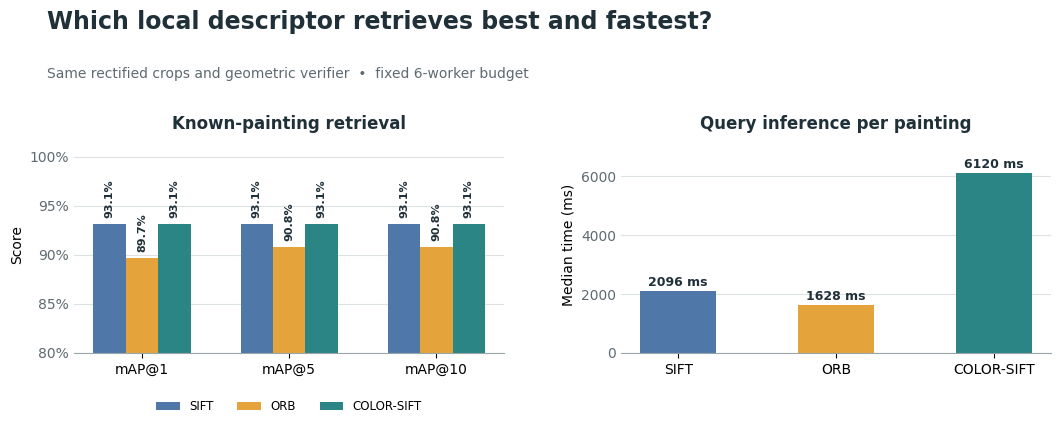

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/descriptor_accuracy_and_speed.png


In [23]:
# Retrieval accuracy and query-side inference cost.
method_colors = {
    "SIFT": "#4F78A8",
    "ORB": "#E5A33B",
    "COLOR-SIFT": TEAL,
}
ordered_descriptor_scores = descriptor_scorecard.set_index("method").loc[DESCRIPTOR_METHODS]

fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.5), facecolor="white")
fig.subplots_adjust(left=0.075, right=0.98, top=0.70, bottom=0.22, wspace=0.27)

metric_names = ["mAP@1", "mAP@5", "mAP@10"]
positions = np.arange(len(metric_names))
bar_width = 0.22
accuracy_values = ordered_descriptor_scores[metric_names].to_numpy(dtype=float)
lower_limit = max(0, np.floor((accuracy_values.min() - 0.05) * 20) / 20)
for method_position, method in enumerate(DESCRIPTOR_METHODS):
    values = ordered_descriptor_scores.loc[method, metric_names].to_numpy(dtype=float)
    offset = (method_position - 1) * bar_width
    bars = axes[0].bar(
        positions + offset, values, bar_width,
        color=method_colors[method], label=method,
    )
    for bar, value in zip(bars, values):
        axes[0].text(
            bar.get_x() + bar.get_width() / 2, value + 0.006, f"{value:.1%}",
            ha="center", va="bottom", rotation=90, fontsize=8,
            fontweight="bold", color=DARK,
        )
axes[0].set_title("Known-painting retrieval", fontsize=12, fontweight="bold", color=DARK)
axes[0].set_xticks(positions, metric_names)
axes[0].set_ylim(lower_limit, 1.02)
axes[0].set_yticks(
    np.linspace(lower_limit, 1.0, 5),
    [f"{value:.0%}" for value in np.linspace(lower_limit, 1.0, 5)],
)
axes[0].set_ylabel("Score")
axes[0].legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.17),
    ncol=3, frameon=False, fontsize=8.5,
)

runtime_values = ordered_descriptor_scores["inference (ms/painting)"].to_numpy(dtype=float)
bars = axes[1].bar(
    np.arange(len(DESCRIPTOR_METHODS)), runtime_values, width=0.48,
    color=[method_colors[method] for method in DESCRIPTOR_METHODS],
)
axes[1].set_title("Query inference per painting", fontsize=12, fontweight="bold", color=DARK)
axes[1].set_xticks(np.arange(len(DESCRIPTOR_METHODS)), DESCRIPTOR_METHODS)
axes[1].set_ylabel("Mean wall time per painting (ms)")
axes[1].set_ylim(0, runtime_values.max() * 1.20)
for bar, value in zip(bars, runtime_values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2, value + runtime_values.max() * 0.03,
        f"{value:.0f} ms", ha="center", fontsize=9, fontweight="bold", color=DARK,
    )

for axis in axes:
    axis.grid(axis="y", color="#DCE2E4", linewidth=0.8)
    axis.set_axisbelow(True)
    axis.spines[["top", "right", "left"]].set_visible(False)
    axis.spines["bottom"].set_color("#9AA5AA")
    axis.tick_params(axis="y", length=0, colors="#5E6A70")

fig.text(0.05, 0.94, "Which local descriptor retrieves best and fastest?", fontsize=17, fontweight="bold", color=DARK)
fig.text(0.05, 0.83, "Same rectified crops, database and geometric verifier", fontsize=10, color="#5E6A70")
figure_path = output_dir / "descriptor_accuracy_and_speed.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {figure_path}")

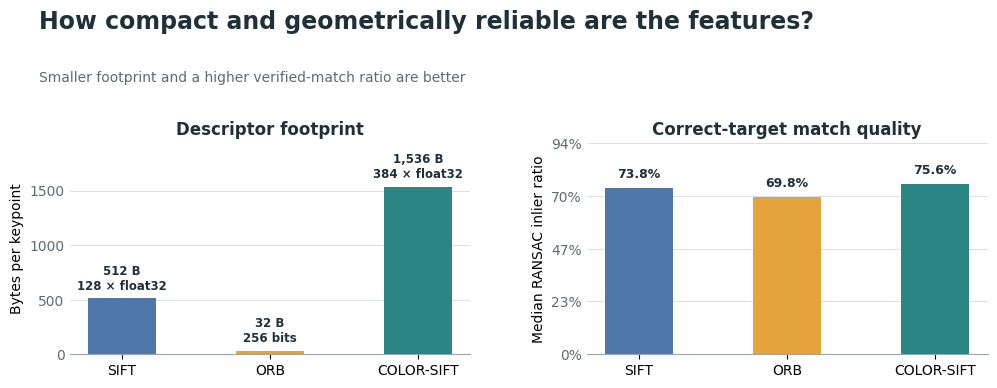

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/descriptor_footprint_and_match_quality.png


In [24]:
# Feature compactness and the quality of matches to the correct BBDD painting.
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.4), facecolor="white")
fig.subplots_adjust(left=0.08, right=0.98, top=0.68, bottom=0.20, wspace=0.29)
colors = [method_colors[method] for method in DESCRIPTOR_METHODS]
x = np.arange(len(DESCRIPTOR_METHODS))

footprints = ordered_descriptor_scores["bytes per keypoint"].to_numpy(dtype=float)
bars = axes[0].bar(x, footprints, width=0.46, color=colors)
axes[0].set_title("Descriptor footprint", fontsize=12, fontweight="bold", color=DARK)
axes[0].set_xticks(x, DESCRIPTOR_METHODS)
axes[0].set_ylabel("Bytes per keypoint")
axes[0].set_ylim(0, footprints.max() * 1.26)
for bar, method, value in zip(bars, DESCRIPTOR_METHODS, footprints):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2, value + footprints.max() * 0.035,
        f"{value:,.0f} B\n{ordered_descriptor_scores.loc[method, 'descriptor format']}",
        ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=DARK,
    )

quality = ordered_descriptor_scores["median GT inlier ratio"].to_numpy(dtype=float)
bars = axes[1].bar(x, quality, width=0.46, color=colors)
axes[1].set_title("Correct-target match quality", fontsize=12, fontweight="bold", color=DARK)
axes[1].set_xticks(x, DESCRIPTOR_METHODS)
axes[1].set_ylabel("Median RANSAC inlier ratio")
axes[1].set_ylim(0, max(0.10, quality.max() * 1.24))
axes[1].set_yticks(
    np.linspace(0, axes[1].get_ylim()[1], 5),
    [f"{value:.0%}" for value in np.linspace(0, axes[1].get_ylim()[1], 5)],
)
for bar, value in zip(bars, quality):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2, value + axes[1].get_ylim()[1] * 0.035,
        f"{value:.1%}", ha="center", va="bottom",
        fontsize=9, fontweight="bold", color=DARK,
    )

for axis in axes:
    axis.grid(axis="y", color="#DCE2E4", linewidth=0.8)
    axis.set_axisbelow(True)
    axis.spines[["top", "right", "left"]].set_visible(False)
    axis.spines["bottom"].set_color("#9AA5AA")
    axis.tick_params(axis="y", length=0, colors="#5E6A70")

fig.text(0.05, 0.94, "How compact and geometrically reliable are the features?", fontsize=17, fontweight="bold", color=DARK)
fig.text(0.05, 0.82, "Smaller footprint and a higher verified-match ratio are better", fontsize=10, color="#5E6A70")
figure_path = output_dir / "descriptor_footprint_and_match_quality.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {figure_path}")

### Descriptor-comparison finding

- **Accuracy:** SIFT and COLOR-SIFT retrieve 27/29 known paintings at rank 1 (93.1%); ORB retrieves 26/29 (89.7%).
- **Efficiency:** ORB is the compact alternative. COLOR-SIFT is about three times larger and slower than SIFT without improving retrieval.
- **Decision:** retain SIFT as the accuracy baseline and ORB as the efficiency baseline. Treat inlier ratio together with the absolute number of verified correspondences.

## Robustness to the provided query augmentations

- **Question:** which descriptor remains reliable for clean queries, hue changes and impulse noise?
- **Contract:** use `augmentations.pkl`, the same rectified crops, BBDD and geometric verifier; evaluate known paintings only.
- **Outputs:** retrieval accuracy and geometrically verified correspondences by augmentation.

In [25]:
# Stratify the descriptor results already computed above; no feature extraction is repeated.
import pickle

with open(QSD_DIR / "augmentations.pkl", "rb") as file:
    query_augmentation_raw = pickle.load(file)

augmentation_name = {
    "None": "Clean",
    "None-MultiplyHue": "Hue shift",
    "UnnamedImpulseNoise": "Impulse noise",
}
query_augmentation = [
    augmentation_name.get(label, str(label))
    for label in query_augmentation_raw
]
AUGMENTATION_ORDER = ["Clean", "Hue shift", "Impulse noise"]

augmentation_rows = []
for method in DESCRIPTOR_METHODS:
    known = descriptor_details[method].query("`ground truth` != -1").copy()
    known["augmentation"] = known["query position"].map(
        lambda position: query_augmentation[int(position)]
    )
    for augmentation in AUGMENTATION_ORDER:
        subset = known[known["augmentation"] == augmentation]
        if subset.empty:
            continue
        rankings = subset["ranked"].tolist()
        references = [[identifier] for identifier in subset["ground truth"].astype(int)]
        augmentation_rows.append(
            {
                "method": method,
                "augmentation": augmentation,
                "known paintings": len(subset),
                "correct at rank 1": int(
                    (subset["rank 1"] == subset["ground truth"]).sum()
                ),
                **{f"mAP@{k}": map_at_k(rankings, references, k) for k in (1, 5, 10)},
                "median GT matches": float(subset["tentative matches to GT"].median()),
                "median GT inliers": float(subset["verified inliers to GT"].median()),
                "median GT inlier ratio": float(subset["GT inlier ratio"].median()),
            }
        )

augmentation_scorecard = pd.DataFrame(augmentation_rows)
display(augmentation_scorecard.round(3))

,method,augmentation,known paintings,correct at rank 1,mAP@1,mAP@5,mAP@10,median GT matches,median GT inliers,median GT inlier ratio
0,SIFT,Clean,8,7,0.875,0.875,0.875,132.5,100.0,0.769
1,SIFT,Hue shift,14,14,1.000,1.000,1.000,205.5,164.5,0.820
2,SIFT,Impulse noise,7,6,0.857,0.857,0.857,104.0,55.0,0.629
3,ORB,Clean,8,7,0.875,0.875,0.875,107.0,73.0,0.679
4,ORB,Hue shift,14,14,1.000,1.000,1.000,242.5,141.0,0.743
5,ORB,Impulse noise,7,5,0.714,0.762,0.762,35.0,18.0,0.529
6,COLOR-SIFT,Clean,8,7,0.875,0.875,0.875,32.0,19.5,0.720
7,COLOR-SIFT,Hue shift,14,14,1.000,1.000,1.000,83.0,63.0,0.765
8,COLOR-SIFT,Impulse noise,7,6,0.857,0.857,0.857,54.0,30.0,0.625


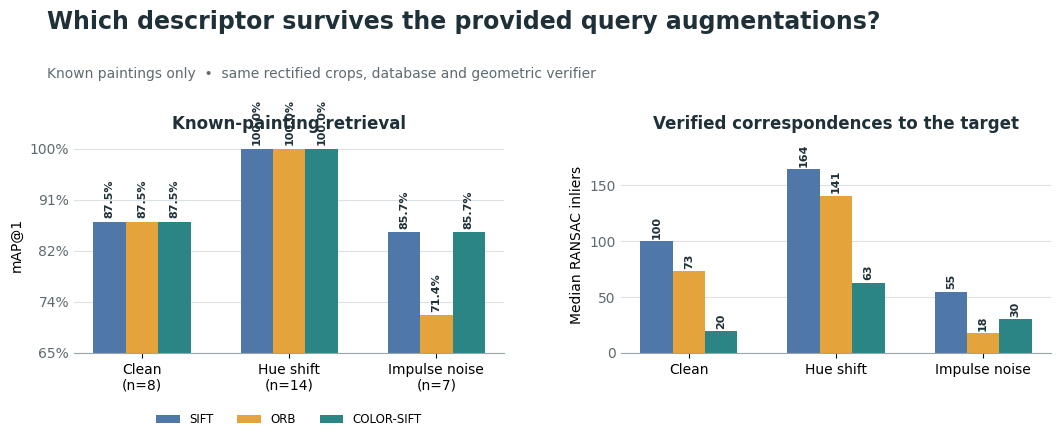

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/descriptor_augmentation_robustness.png


In [27]:
# Slide-ready comparison of retrieval robustness and verified geometric evidence.
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.5), facecolor="white")
fig.subplots_adjust(left=0.075, right=0.98, top=0.70, bottom=0.22, wspace=0.27)
positions = np.arange(len(AUGMENTATION_ORDER))
bar_width = 0.22

score_matrix = np.asarray([
    [
        augmentation_scorecard.query(
            "method == @method and augmentation == @augmentation"
        )["mAP@1"].iloc[0]
        for augmentation in AUGMENTATION_ORDER
    ]
    for method in DESCRIPTOR_METHODS
], dtype=float)
lower_limit = max(0, np.floor((score_matrix.min() - 0.05) * 20) / 20)

for method_position, method in enumerate(DESCRIPTOR_METHODS):
    values = score_matrix[method_position]
    offset = (method_position - 1) * bar_width
    bars = axes[0].bar(
        positions + offset, values, bar_width,
        color=method_colors[method], label=method,
    )
    for bar, value in zip(bars, values):
        axes[0].text(
            bar.get_x() + bar.get_width() / 2, value + 0.006, f"{value:.1%}",
            ha="center", va="bottom", rotation=90, fontsize=8,
            fontweight="bold", color=DARK,
        )

first_method = DESCRIPTOR_METHODS[0]
group_counts = (
    augmentation_scorecard.query("method == @first_method")
    .set_index("augmentation")["known paintings"]
    .reindex(AUGMENTATION_ORDER)
)
axes[0].set_title("Known-painting retrieval", fontsize=12, fontweight="bold", color=DARK)
axes[0].set_xticks(
    positions,
    [f"{name}\n(n={int(group_counts[name])})" for name in AUGMENTATION_ORDER],
)
axes[0].set_ylabel("mAP@1")
axes[0].set_ylim(lower_limit, 1.02)
axes[0].set_yticks(
    np.linspace(lower_limit, 1.0, 5),
    [f"{value:.0%}" for value in np.linspace(lower_limit, 1.0, 5)],
)
axes[0].legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.23),
    ncol=3, frameon=False, fontsize=8.5,
)

for method_position, method in enumerate(DESCRIPTOR_METHODS):
    values = np.asarray([
        augmentation_scorecard.query(
            "method == @method and augmentation == @augmentation"
        )["median GT inliers"].iloc[0]
        for augmentation in AUGMENTATION_ORDER
    ], dtype=float)
    offset = (method_position - 1) * bar_width
    bars = axes[1].bar(
        positions + offset, values, bar_width, color=method_colors[method],
    )
    for bar, value in zip(bars, values):
        axes[1].text(
            bar.get_x() + bar.get_width() / 2, value + 2, f"{value:.0f}",
            ha="center", va="bottom", rotation=90, fontsize=8,
            fontweight="bold", color=DARK,
        )

axes[1].set_title("Verified correspondences to the target", fontsize=12, fontweight="bold", color=DARK)
axes[1].set_xticks(positions, AUGMENTATION_ORDER)
axes[1].set_ylabel("Median RANSAC inliers")
axes[1].set_ylim(0, max(10, axes[1].get_ylim()[1] * 1.12))

for axis in axes:
    axis.grid(axis="y", color="#DCE2E4", linewidth=0.8)
    axis.set_axisbelow(True)
    axis.spines[["top", "right", "left"]].set_visible(False)
    axis.spines["bottom"].set_color("#9AA5AA")
    axis.tick_params(axis="y", length=0, colors="#5E6A70")

fig.text(0.05, 0.94, "Which descriptor survives the provided query augmentations?", fontsize=17, fontweight="bold", color=DARK)
fig.text(0.05, 0.83, "Known paintings only  •  same rectified crops, database and geometric verifier", fontsize=10, color="#5E6A70")
figure_path = output_dir / "descriptor_augmentation_robustness.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {figure_path}")

### Augmentation finding

- **Clean:** all descriptors retrieve 7/8 paintings at rank 1 (87.5%).
- **Hue shift:** all retrieve 14/14, but this unbalanced grouping does not prove that hue changes improve retrieval.
- **Impulse noise:** SIFT and COLOR-SIFT retain 6/7 (85.7%); ORB falls to 5/7 (71.4%) and only 18 median verified inliers.
- **Next:** apply the same controlled rotation, blur, downsampling, cropping and occlusion to every known crop.

## Controlled robustness test

- **Question:** how much accuracy and verified geometric evidence survive when every known painting receives the same distortion?
- **Population:** all 29 known rectified painting crops; examples include one single-painting and one multi-painting query.
- **Perturbations:** 10° rotation, Gaussian blur, 50% downsampling, 10% border crop and 15% central occlusion.

In [30]:
# Define deterministic perturbations and collect the known rectified crops.
CONTROLLED_VARIANTS = [
    "Original",
    "Rotation 10°",
    "Gaussian blur",
    "Downsample 50%",
    "Crop 10%",
    "Occlusion 15%",
]


def apply_controlled_perturbation(image, mask, variant):
    image = image.copy()
    height, width = image.shape[:2]
    if mask is None:
        mask = np.full((height, width), 255, dtype=np.uint8)
    else:
        mask = (np.asarray(mask) > 0).astype(np.uint8) * 255

    if variant == "Original":
        return image, mask

    if variant == "Rotation 10°":
        transform = cv2.getRotationMatrix2D((width / 2, height / 2), 10, 1.0)
        image = cv2.warpAffine(
            image, transform, (width, height),
            flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101,
        )
        mask = cv2.warpAffine(
            mask, transform, (width, height),
            flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0,
        )
        return image, mask

    if variant == "Gaussian blur":
        return cv2.GaussianBlur(image, (0, 0), sigmaX=1.5, sigmaY=1.5), mask

    if variant == "Downsample 50%":
        small_size = (max(2, width // 2), max(2, height // 2))
        small_image = cv2.resize(image, small_size, interpolation=cv2.INTER_AREA)
        small_mask = cv2.resize(mask, small_size, interpolation=cv2.INTER_NEAREST)
        image = cv2.resize(small_image, (width, height), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(small_mask, (width, height), interpolation=cv2.INTER_NEAREST)
        return image, mask

    if variant == "Crop 10%":
        margin_y = max(1, int(round(height * 0.10)))
        margin_x = max(1, int(round(width * 0.10)))
        image = image[margin_y:height - margin_y, margin_x:width - margin_x]
        mask = mask[margin_y:height - margin_y, margin_x:width - margin_x]
        image = cv2.resize(image, (width, height), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (width, height), interpolation=cv2.INTER_NEAREST)
        return image, mask

    if variant == "Occlusion 15%":
        occlusion_width = max(1, int(round(width * 0.40)))
        occlusion_height = max(1, int(round(height * 0.375)))
        x0 = (width - occlusion_width) // 2
        y0 = (height - occlusion_height) // 2
        valid_pixels = image[mask > 0]
        fill = (
            np.median(valid_pixels, axis=0).astype(np.uint8)
            if len(valid_pixels)
            else np.median(image.reshape(-1, 3), axis=0).astype(np.uint8)
        )
        image[y0:y0 + occlusion_height, x0:x0 + occlusion_width] = fill
        return image, mask

    raise ValueError(f"Unsupported controlled perturbation: {variant}")


controlled_records = []
for query_position, (parts, references) in enumerate(zip(rectified_parts, ground_truth)):
    for painting_position, (part, ground_truth_id) in enumerate(zip(parts, references)):
        if int(ground_truth_id) == -1:
            continue
        controlled_records.append(
            {
                "query position": query_position,
                "query": int(qsd.ids[query_position]),
                "painting position": painting_position,
                "ground truth": int(ground_truth_id),
                "crop": part["crop"],
                "mask": part["mask"],
            }
        )

print(f"Known painting crops: {len(controlled_records)}")

Known painting crops: 29


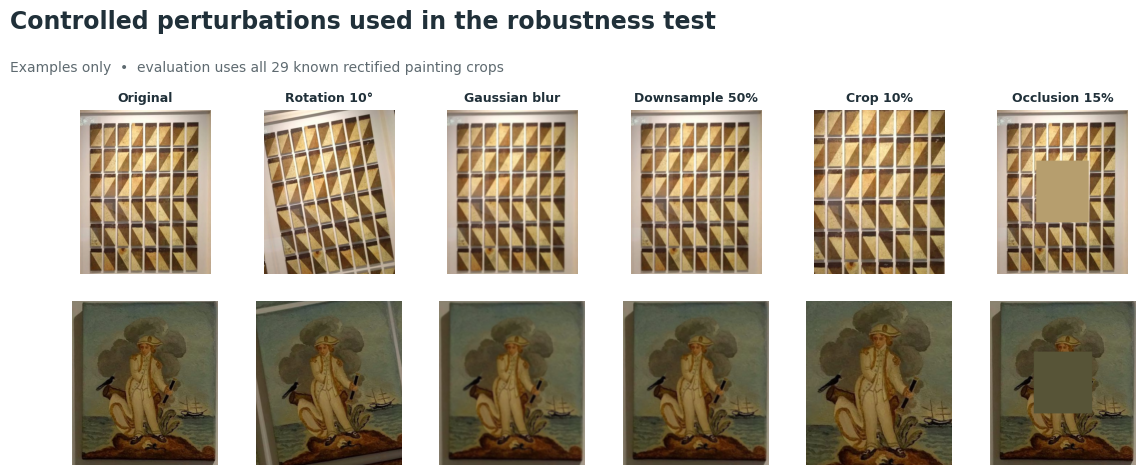

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/controlled_augmentation_examples.png


In [31]:
# Show exactly what is perturbed: one crop from a single-painting query and one from a multi-painting query.
single_example = next(
    record for record in controlled_records
    if len(ground_truth[record["query position"]]) == 1
)
multiple_example = next(
    record for record in controlled_records
    if len(ground_truth[record["query position"]]) > 1
)
examples = [single_example, multiple_example]
row_names = ["Single-painting query", "Multi-painting query"]

fig, axes = plt.subplots(2, len(CONTROLLED_VARIANTS), figsize=(12, 4.8), facecolor="white")
fig.subplots_adjust(left=0.08, right=0.99, top=0.78, bottom=0.04, hspace=0.16, wspace=0.05)

for row, (record, row_name) in enumerate(zip(examples, row_names)):
    for column, variant in enumerate(CONTROLLED_VARIANTS):
        transformed, _ = apply_controlled_perturbation(
            record["crop"], record["mask"], variant
        )
        axis = axes[row, column]
        axis.imshow(cv2.cvtColor(transformed, cv2.COLOR_BGR2RGB))
        if row == 0:
            axis.set_title(variant, fontsize=9, fontweight="bold", color=DARK, pad=6)
        axis.axis("off")
    axes[row, 0].set_ylabel(
        f"{row_name}\nQ{record['query']:05d} • painting {record['painting position'] + 1}",
        fontsize=8.5, fontweight="bold", color=DARK, labelpad=12,
    )

fig.text(0.04, 0.95, "Controlled perturbations used in the robustness test", fontsize=17, fontweight="bold", color=DARK)
fig.text(0.04, 0.86, "Examples only  •  evaluation uses all 29 known rectified painting crops", fontsize=10, color="#5E6A70")
figure_path = output_dir / "controlled_augmentation_examples.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {figure_path}")

In [32]:
# Evaluate every descriptor on every controlled variant. Methods run sequentially; images run in parallel.
import gc

N_CONTROLLED_WORKERS = min(4, N_WORKERS)


def extract_controlled_feature(record, variant, method):
    image, mask = apply_controlled_perturbation(
        record["crop"], record["mask"], variant
    )
    feature = extract_local_feature_record(image, method, mask, N_FEATURES)
    return {
        "query position": record["query position"],
        "query": record["query"],
        "painting position": record["painting position"],
        "ground truth": record["ground truth"],
        "variant": variant,
        "feature": feature,
    }


controlled_scores = []
controlled_details = {}
for method in DESCRIPTOR_METHODS:
    print(f"Evaluating controlled perturbations with {method}...")
    norm = DESCRIPTOR_SPECIFICATIONS[method]["norm"]

    database_records = Parallel(n_jobs=N_CONTROLLED_WORKERS, backend="loky")(
        delayed(extract_path_feature_record)(path, method, N_FEATURES)
        for path in bbdd.paths
    )
    database_features = {
        int(identifier): feature
        for identifier, feature in zip(bbdd.ids, database_records)
    }

    transformed_features = Parallel(n_jobs=N_CONTROLLED_WORKERS, backend="loky")(
        delayed(extract_controlled_feature)(record, variant, method)
        for variant in CONTROLLED_VARIANTS
        for record in controlled_records
    )

    def evaluate_controlled_feature(item):
        feature = item["feature"]
        ground_truth_id = item["ground truth"]
        result = rank_descriptor_database(feature, database_features, norm)
        ranking = result["ranked"]
        query_indices, reference_indices = accepted_descriptor_matches(
            feature["descriptors"],
            database_features[ground_truth_id]["descriptors"],
            norm,
        )
        verified_inliers = ransac_inliers(
            feature["points"],
            database_features[ground_truth_id]["points"],
            query_indices, reference_indices, threshold=RANSAC_THRESHOLD,
        )
        return {
            "method": method,
            "variant": item["variant"],
            "query position": item["query position"],
            "query": item["query"],
            "painting position": item["painting position"],
            "ground truth": ground_truth_id,
            "ranked": ranking,
            "rank 1": int(ranking[0]),
            "tentative matches to GT": len(query_indices),
            "verified inliers to GT": verified_inliers,
            "GT inlier ratio": verified_inliers / max(len(query_indices), 1),
        }

    rows = Parallel(n_jobs=N_CONTROLLED_WORKERS, backend="threading")(
        delayed(evaluate_controlled_feature)(item)
        for item in transformed_features
    )
    method_details = pd.DataFrame(rows)
    controlled_details[method] = method_details

    for variant in CONTROLLED_VARIANTS:
        subset = method_details[method_details["variant"] == variant]
        rankings = subset["ranked"].tolist()
        references = [[identifier] for identifier in subset["ground truth"].astype(int)]
        controlled_scores.append(
            {
                "method": method,
                "variant": variant,
                "paintings": len(subset),
                "correct at rank 1": int(
                    (subset["rank 1"] == subset["ground truth"]).sum()
                ),
                **{f"mAP@{k}": map_at_k(rankings, references, k) for k in (1, 5, 10)},
                "median GT matches": float(subset["tentative matches to GT"].median()),
                "median GT inliers": float(subset["verified inliers to GT"].median()),
                "median GT inlier ratio": float(subset["GT inlier ratio"].median()),
            }
        )

    del transformed_features, database_features, database_records
    gc.collect()

controlled_scorecard = pd.DataFrame(controlled_scores)
display(controlled_scorecard.round(3))

Evaluating controlled perturbations with SIFT...


/Users/femiloye/miniconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Evaluating controlled perturbations with ORB...
Evaluating controlled perturbations with COLOR-SIFT...


/Users/femiloye/miniconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,method,variant,paintings,correct at rank 1,mAP@1,mAP@5,mAP@10,median GT matches,median GT inliers,median GT inlier ratio
0,SIFT,Original,29,27,0.931,0.931,0.931,163.0,113.0,0.738
1,SIFT,Rotation 10°,29,27,0.931,0.931,0.931,147.0,93.0,0.761
2,SIFT,Gaussian blur,29,26,0.897,0.897,0.897,59.0,34.0,0.697
3,SIFT,Downsample 50%,29,27,0.931,0.931,0.931,99.0,63.0,0.723
4,SIFT,Crop 10%,29,26,0.897,0.914,0.914,146.0,93.0,0.815
5,SIFT,Occlusion 15%,29,24,0.828,0.828,0.828,96.0,64.0,0.763
6,ORB,Original,29,26,0.897,0.908,0.908,123.0,88.0,0.698
7,ORB,Rotation 10°,29,26,0.897,0.897,0.897,104.0,73.0,0.669
8,ORB,Gaussian blur,29,23,0.793,0.793,0.797,50.0,26.0,0.639
9,ORB,Downsample 50%,29,25,0.862,0.871,0.871,83.0,48.0,0.678


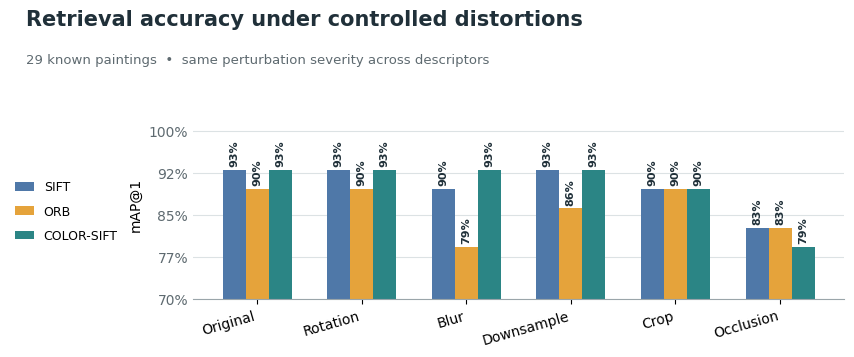

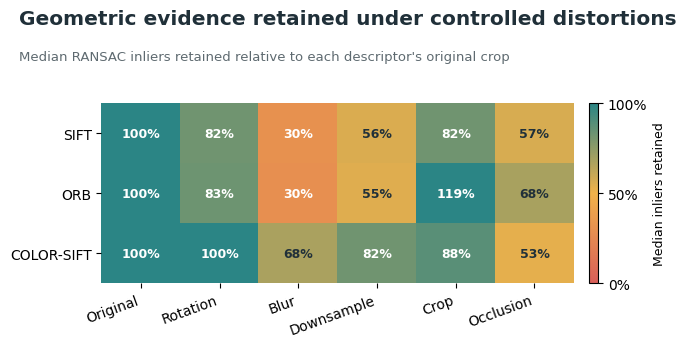

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/controlled_descriptor_retrieval.png
Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/controlled_descriptor_inlier_retention.png


In [ ]:
#summary: retrieval accuracy and retention of verified geometric evidence.
from matplotlib.colors import LinearSegmentedColormap

short_variant_names = [
    "Original", "Rotation", "Blur", "Downsample", "Crop", "Occlusion"
]
positions = np.arange(len(CONTROLLED_VARIANTS))
bar_width = 0.22
score_matrix = np.asarray([
    [
        controlled_scorecard.query(
            "method == @method and variant == @variant"
        )["mAP@1"].iloc[0]
        for variant in CONTROLLED_VARIANTS
    ]
    for method in DESCRIPTOR_METHODS
], dtype=float)
inlier_matrix = np.asarray([
    [
        controlled_scorecard.query(
            "method == @method and variant == @variant"
        )["median GT inliers"].iloc[0]
        for variant in CONTROLLED_VARIANTS
    ]
    for method in DESCRIPTOR_METHODS
], dtype=float)
inlier_retention = inlier_matrix / np.maximum(inlier_matrix[:, [0]], 1)

# Figure 1: retrieval accuracy.
lower_limit = max(0, np.floor((score_matrix.min() - 0.05) * 20) / 20)
fig, axis = plt.subplots(figsize=(8.8, 3.8), facecolor="white")
fig.subplots_adjust(left=0.24, right=0.98, top=0.72, bottom=0.22)
for method_position, method in enumerate(DESCRIPTOR_METHODS):
    values = score_matrix[method_position]
    offset = (method_position - 1) * bar_width
    bars = axis.bar(
        positions + offset, values, bar_width,
        color=method_colors[method], label=method,
    )
    for bar, value in zip(bars, values):
        axis.text(
            bar.get_x() + bar.get_width() / 2, value + 0.006, f"{value:.0%}",
            ha="center", va="bottom", rotation=90, fontsize=8,
            fontweight="bold", color=DARK,
        )
axis.set_xticks(positions, short_variant_names, rotation=16, ha="right")
axis.set_ylabel("mAP@1")
axis.set_ylim(lower_limit, 1.04)
axis.set_yticks(
    np.linspace(lower_limit, 1.0, 5),
    [f"{value:.0%}" for value in np.linspace(lower_limit, 1.0, 5)],
)
axis.grid(axis="y", color="#DCE2E4", linewidth=0.8)
axis.set_axisbelow(True)
axis.spines[["top", "right", "left"]].set_visible(False)
axis.spines["bottom"].set_color("#9AA5AA")
axis.tick_params(axis="y", length=0, colors="#5E6A70")
handles, labels = axis.get_legend_handles_labels()
fig.legend(
    handles, labels, loc="center left", bbox_to_anchor=(0.025, 0.45),
    frameon=False, fontsize=9, ncol=1, handlelength=1.5, labelspacing=0.9,
)
fig.text(0.05, 0.94, "Retrieval accuracy under controlled distortions", fontsize=15, fontweight="bold", color=DARK)
fig.text(0.05, 0.84, "29 known paintings  •  same perturbation severity across descriptors", fontsize=9.5, color="#5E6A70")
retrieval_figure_path = output_dir / "controlled_descriptor_retrieval.png"
fig.savefig(retrieval_figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# Figure 2: retention of geometrically verified local evidence.
retention_cmap = LinearSegmentedColormap.from_list(
    "retention", ["#D95F59", "#F1B24A", TEAL]
)
fig, axis = plt.subplots(figsize=(7.2, 3.6), facecolor="white")
fig.subplots_adjust(left=0.17, right=0.88, top=0.72, bottom=0.22)
image = axis.imshow(inlier_retention, vmin=0, vmax=1, cmap=retention_cmap, aspect="auto")
axis.set_xticks(np.arange(len(CONTROLLED_VARIANTS)), short_variant_names, rotation=20, ha="right")
axis.set_yticks(np.arange(len(DESCRIPTOR_METHODS)), DESCRIPTOR_METHODS)
for row in range(inlier_retention.shape[0]):
    for column in range(inlier_retention.shape[1]):
        value = inlier_retention[row, column]
        axis.text(
            column, row, f"{value:.0%}", ha="center", va="center",
            fontsize=9, fontweight="bold",
            color="white" if value < 0.45 or value > 0.82 else DARK,
        )
for spine in axis.spines.values():
    spine.set_visible(False)
colorbar = fig.colorbar(image, ax=axis, fraction=0.046, pad=0.03)
colorbar.set_label("Median inliers retained", fontsize=9)
colorbar.set_ticks([0, 0.5, 1])
colorbar.set_ticklabels(["0%", "50%", "100%"])
fig.text(0.055, 0.94, "Geometric evidence retained under controlled distortions", fontsize=14.5, fontweight="bold", color=DARK)
fig.text(0.055, 0.84, "Median RANSAC inliers retained relative to each descriptor's original crop", fontsize=9.5, color="#5E6A70")
retention_figure_path = output_dir / "controlled_descriptor_inlier_retention.png"
fig.savefig(retention_figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print(f"Saved: {retrieval_figure_path}")
print(f"Saved: {retention_figure_path}")

### Controlled-robustness finding

- **Most robust descriptor:** _record after running_.
- **Most damaging perturbation:** _record after running_.
- **Accuracy–efficiency decision:** _record after running_.

## Matching and geometric-verification ablation

- **Question:** which tentative-matching rule and verification stage best support SIFT retrieval?
- **Fixed:** refined detections, geometric rectification, SIFT, 3,000-feature cap and the same BBDD.
- **Compared:** ratio test, mutual nearest neighbours and ratio + mutual matching, before and after RANSAC.

In [40]:
# Extract SIFT once; every matching variant receives exactly the same features.
flat_matching_parts = [part for query_parts in rectified_parts for part in query_parts]
matching_query_features_flat = Parallel(n_jobs=N_WORKERS, backend="loky")(
    delayed(extract_local_feature_record)(
        part["crop"], "SIFT", part["mask"], N_FEATURES
    )
    for part in flat_matching_parts
)

feature_iterator = iter(matching_query_features_flat)
matching_query_features = [
    [next(feature_iterator) for _ in query_parts]
    for query_parts in rectified_parts
]
matching_database_records = Parallel(n_jobs=N_WORKERS, backend="loky")(
    delayed(extract_path_feature_record)(path, "SIFT", N_FEATURES)
    for path in bbdd.paths
)
matching_database_features = {
    int(identifier): feature
    for identifier, feature in zip(bbdd.ids, matching_database_records)
}
matching_database_paths = {
    int(identifier): path for identifier, path in zip(bbdd.ids, bbdd.paths)
}
matching_tasks = [
    (query_position, painting_position, feature, int(ground_truth_id))
    for query_position, (features, references) in enumerate(
        zip(matching_query_features, ground_truth)
    )
    for painting_position, (feature, ground_truth_id) in enumerate(
        zip(features, references)
    )
]
print(
    f"Cached {len(matching_query_features_flat)} query paintings and "
    f"{len(matching_database_features)} database paintings."
)

/Users/femiloye/miniconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Cached 39 query paintings and 287 database paintings.


In [44]:
# Evaluate tentative matching and RANSAC without changing the SIFT features.
MATCHING_STRATEGIES = ["Ratio test", "Mutual nearest", "Ratio + mutual"]
MATCHING_VARIANTS = ["Tentative matches", "RANSAC verified"]
MATCHING_SHORTLIST = 30


def ratio_test_matches(query_descriptors, reference_descriptors, ratio=RATIO_THRESHOLD):
    pairs = cv2.BFMatcher(cv2.NORM_L2).knnMatch(
        query_descriptors, reference_descriptors, k=2
    )
    return [
        pair[0] for pair in pairs
        if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance
    ]


def accepted_sift_matches(query_descriptors, reference_descriptors, strategy):
    if (
        query_descriptors is None or reference_descriptors is None
        or len(query_descriptors) < 2 or len(reference_descriptors) < 2
    ):
        return np.zeros(0, dtype=int), np.zeros(0, dtype=int)

    if strategy == "Ratio test":
        accepted = ratio_test_matches(query_descriptors, reference_descriptors)
    elif strategy == "Mutual nearest":
        accepted = cv2.BFMatcher(cv2.NORM_L2, crossCheck=True).match(
            query_descriptors, reference_descriptors
        )
    elif strategy == "Ratio + mutual":
        forward = ratio_test_matches(query_descriptors, reference_descriptors)
        reverse = ratio_test_matches(reference_descriptors, query_descriptors)
        reverse_pairs = {(match.trainIdx, match.queryIdx) for match in reverse}
        accepted = [
            match for match in forward
            if (match.queryIdx, match.trainIdx) in reverse_pairs
        ]
    else:
        raise ValueError(f"Unsupported matching strategy: {strategy}")

    return (
        np.asarray([match.queryIdx for match in accepted], dtype=int),
        np.asarray([match.trainIdx for match in accepted], dtype=int),
    )


def rank_sift_matching_variants(query_feature, strategy, ground_truth_id):
    started = time.perf_counter()
    matches = {
        identifier: accepted_sift_matches(
            query_feature["descriptors"], reference["descriptors"], strategy
        )
        for identifier, reference in matching_database_features.items()
    }
    matching_ms = (time.perf_counter() - started) * 1000
    tentative_ranking = sorted(
        matching_database_features,
        key=lambda identifier: len(matches[identifier][0]),
        reverse=True,
    )

    started = time.perf_counter()
    candidates = tentative_ranking[:MATCHING_SHORTLIST]
    inliers = {
        identifier: ransac_inliers(
            query_feature["points"],
            matching_database_features[identifier]["points"],
            *matches[identifier],
            threshold=RANSAC_THRESHOLD,
        )
        for identifier in candidates
    }
    verification_ms = (time.perf_counter() - started) * 1000
    verified_ranking = sorted(
        matching_database_features,
        key=lambda identifier: (
            inliers.get(identifier, -1), len(matches[identifier][0])
        ),
        reverse=True,
    )
    inlier_scores = sorted(inliers.values(), reverse=True)
    known = ground_truth_id != -1
    return {
        "tentative ranked": [int(identifier) for identifier in tentative_ranking[:10]],
        "verified ranked": [int(identifier) for identifier in verified_ranking[:10]],
        "matching ms": matching_ms,
        "verification ms": verification_ms,
        "best tentative": int(len(matches[tentative_ranking[0]][0])),
        "best inliers": int(inlier_scores[0]) if inlier_scores else 0,
        "second inliers": int(inlier_scores[1]) if len(inlier_scores) > 1 else 0,
        "GT tentative": (
            int(len(matches[ground_truth_id][0])) if known else np.nan
        ),
        "GT inliers": (
            int(inliers.get(ground_truth_id, 0)) if known else np.nan
        ),
    }


def evaluate_matching_task(strategy, task):
    query_position, painting_position, feature, ground_truth_id = task
    result = rank_sift_matching_variants(feature, strategy, ground_truth_id)
    return {
        "strategy": strategy,
        "query position": query_position,
        "query": int(qsd.ids[query_position]),
        "painting position": painting_position,
        "ground truth": ground_truth_id,
        **result,
    }


matching_frames = []
for strategy in MATCHING_STRATEGIES:
    print(f"Evaluating {strategy}...")
    rows = Parallel(n_jobs=N_WORKERS, backend="threading")(
        delayed(evaluate_matching_task)(strategy, task)
        for task in matching_tasks
    )
    matching_frames.append(pd.DataFrame(rows))

matching_details = pd.concat(matching_frames, ignore_index=True)
matching_score_rows = []
for strategy in MATCHING_STRATEGIES:
    strategy_rows = matching_details[matching_details["strategy"] == strategy]
    known_rows = strategy_rows[strategy_rows["ground truth"] != -1]
    references = [[identifier] for identifier in known_rows["ground truth"].astype(int)]
    for variant in MATCHING_VARIANTS:
        verified = variant == "RANSAC verified"
        ranking_column = "verified ranked" if verified else "tentative ranked"
        rankings = known_rows[ranking_column].tolist()
        rank_one = [ranking[0] for ranking in rankings]
        matching_score_rows.append(
            {
                "strategy": strategy,
                "verification": variant,
                "correct at rank 1": int(
                    np.sum(np.asarray(rank_one) == known_rows["ground truth"].to_numpy())
                ),
                **{f"mAP@{k}": map_at_k(rankings, references, k) for k in (1, 5, 10)},
                "median GT tentative": float(known_rows["GT tentative"].median()),
                "median GT inliers": float(known_rows["GT inliers"].median()),
            }
        )

matching_scorecard = pd.DataFrame(matching_score_rows)
display(matching_scorecard.round(3))

Evaluating Ratio test...
Evaluating Mutual nearest...
Evaluating Ratio + mutual...


,strategy,verification,correct at rank 1,mAP@1,mAP@5,mAP@10,median GT tentative,median GT inliers
0,Ratio test,Tentative matches,20,0.690,0.759,0.763,163.0,113.0
1,Ratio test,RANSAC verified,27,0.931,0.931,0.931,163.0,113.0
2,Mutual nearest,Tentative matches,16,0.552,0.598,0.612,250.0,115.0
3,Mutual nearest,RANSAC verified,24,0.828,0.828,0.828,250.0,115.0
4,Ratio + mutual,Tentative matches,27,0.931,0.931,0.931,130.0,100.0
5,Ratio + mutual,RANSAC verified,27,0.931,0.931,0.931,130.0,100.0


In [45]:
# Measure latency sequentially so parallel worker contention cannot distort it.
known_matching_tasks = [task for task in matching_tasks if task[3] != -1]
LATENCY_SAMPLE_SIZE = min(8, len(known_matching_tasks))
latency_positions = np.linspace(
    0, len(known_matching_tasks) - 1, LATENCY_SAMPLE_SIZE, dtype=int
)
latency_tasks = [known_matching_tasks[position] for position in latency_positions]

latency_rows = []
for strategy in MATCHING_STRATEGIES:
    print(f"Benchmarking {strategy} sequentially...")
    for task in latency_tasks:
        result = rank_sift_matching_variants(task[2], strategy, task[3])
        latency_rows.extend(
            [
                {
                    "strategy": strategy,
                    "verification": "Tentative matches",
                    "latency ms": result["matching ms"],
                },
                {
                    "strategy": strategy,
                    "verification": "RANSAC verified",
                    "latency ms": (
                        result["matching ms"] + result["verification ms"]
                    ),
                },
            ]
        )

matching_latency = pd.DataFrame(latency_rows)
matching_latency_summary = (
    matching_latency
    .groupby(["strategy", "verification"], as_index=False)["latency ms"]
    .median()
    .rename(columns={"latency ms": "median latency (ms/painting)"})
)
display(matching_latency_summary.round(1))

Benchmarking Ratio test sequentially...
Benchmarking Mutual nearest sequentially...
Benchmarking Ratio + mutual sequentially...


,strategy,verification,median latency (ms/painting)
0,Mutual nearest,RANSAC verified,10494.6
1,Mutual nearest,Tentative matches,10038.7
2,Ratio + mutual,RANSAC verified,10281.1
3,Ratio + mutual,Tentative matches,10275.4
4,Ratio test,RANSAC verified,5339.0
5,Ratio test,Tentative matches,5091.9


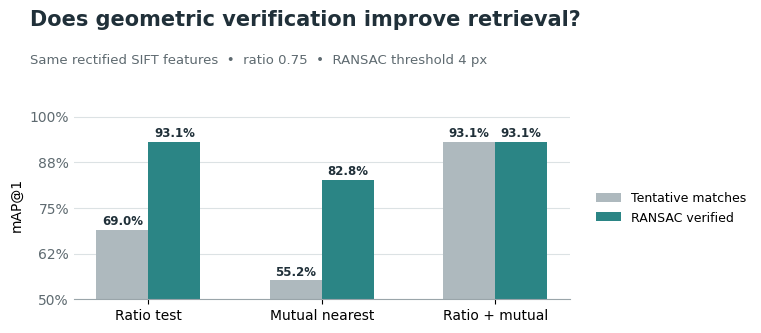

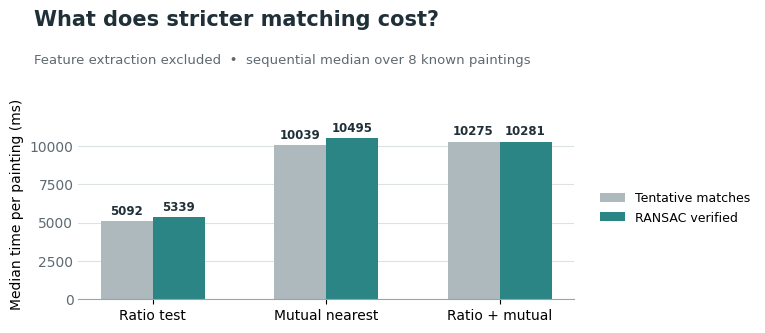

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/matching_ablation_accuracy.png
Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/matching_ablation_runtime.png


In [ ]:
# Two compact: accuracy and matching cost.
strategy_colors = {
    "Tentative matches": "#AEB9BE",
    "RANSAC verified": TEAL,
}
positions = np.arange(len(MATCHING_STRATEGIES))
bar_width = 0.30

fig, axis = plt.subplots(figsize=(7.4, 3.8), facecolor="white")
fig.subplots_adjust(left=0.11, right=0.78, top=0.72, bottom=0.22)
for variant_position, variant in enumerate(MATCHING_VARIANTS):
    values = np.asarray([
        matching_scorecard.query(
            "strategy == @strategy and verification == @variant"
        )["mAP@1"].iloc[0]
        for strategy in MATCHING_STRATEGIES
    ])
    bars = axis.bar(
        positions + (variant_position - 0.5) * bar_width, values, bar_width,
        color=strategy_colors[variant], label=variant,
    )
    for bar, value in zip(bars, values):
        axis.text(
            bar.get_x() + bar.get_width() / 2, value + 0.006, f"{value:.1%}",
            ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=DARK,
        )
lower_limit = max(0, np.floor((matching_scorecard["mAP@1"].min() - 0.05) * 20) / 20)
axis.set_ylim(lower_limit, 1.02)
axis.set_yticks(
    np.linspace(lower_limit, 1.0, 5),
    [f"{value:.0%}" for value in np.linspace(lower_limit, 1.0, 5)],
)
axis.set_xticks(positions, MATCHING_STRATEGIES)
axis.set_ylabel("mAP@1")
axis.grid(axis="y", color="#DCE2E4", linewidth=0.8)
axis.set_axisbelow(True)
axis.spines[["top", "right", "left"]].set_visible(False)
axis.spines["bottom"].set_color("#9AA5AA")
axis.tick_params(axis="y", length=0, colors="#5E6A70")
fig.legend(loc="center left", bbox_to_anchor=(0.80, 0.46), frameon=False, fontsize=9)
fig.text(0.05, 0.94, "Does geometric verification improve retrieval?", fontsize=15, fontweight="bold", color=DARK)
fig.text(0.05, 0.84, "Same rectified SIFT features  •  ratio 0.75  •  RANSAC threshold 4 px", fontsize=9.5, color="#5E6A70")
matching_accuracy_path = output_dir / "matching_ablation_accuracy.png"
fig.savefig(matching_accuracy_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

fig, axis = plt.subplots(figsize=(7.4, 3.8), facecolor="white")
fig.subplots_adjust(left=0.11, right=0.78, top=0.72, bottom=0.22)
for variant_position, variant in enumerate(MATCHING_VARIANTS):
    values = np.asarray([
        matching_latency_summary.query(
            "strategy == @strategy and verification == @variant"
        )["median latency (ms/painting)"].iloc[0]
        for strategy in MATCHING_STRATEGIES
    ])
    bars = axis.bar(
        positions + (variant_position - 0.5) * bar_width, values, bar_width,
        color=strategy_colors[variant], label=variant,
    )
    for bar, value in zip(bars, values):
        axis.text(
            bar.get_x() + bar.get_width() / 2, value + values.max() * 0.025,
            f"{value:.0f}", ha="center", va="bottom",
            fontsize=8.5, fontweight="bold", color=DARK,
        )
axis.set_xticks(positions, MATCHING_STRATEGIES)
axis.set_ylabel("Median time per painting (ms)")
axis.set_ylim(
    0, matching_latency_summary["median latency (ms/painting)"].max() * 1.18
)
axis.grid(axis="y", color="#DCE2E4", linewidth=0.8)
axis.set_axisbelow(True)
axis.spines[["top", "right", "left"]].set_visible(False)
axis.spines["bottom"].set_color("#9AA5AA")
axis.tick_params(axis="y", length=0, colors="#5E6A70")
fig.legend(loc="center left", bbox_to_anchor=(0.80, 0.46), frameon=False, fontsize=9)
fig.text(0.05, 0.94, "What does stricter matching cost?", fontsize=15, fontweight="bold", color=DARK)
fig.text(0.05, 0.84, f"Feature extraction excluded  •  sequential median over {LATENCY_SAMPLE_SIZE} known paintings", fontsize=9.5, color="#5E6A70")
matching_runtime_path = output_dir / "matching_ablation_runtime.png"
fig.savefig(matching_runtime_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print(f"Saved: {matching_accuracy_path}")
print(f"Saved: {matching_runtime_path}")

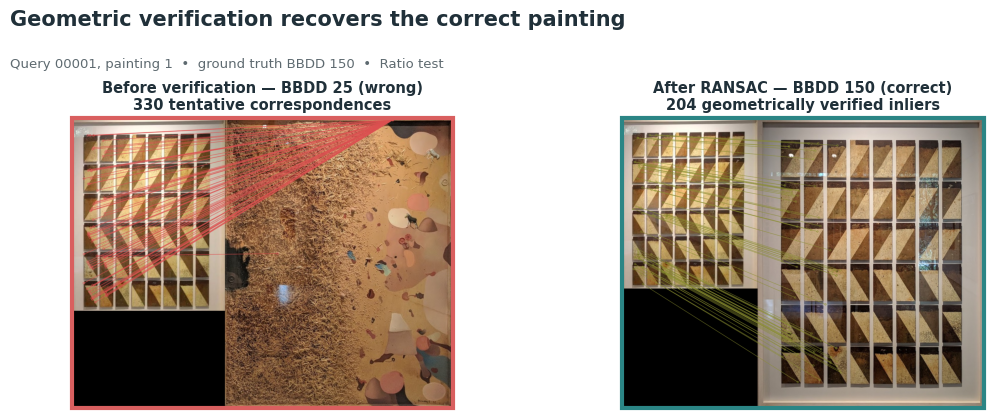

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/matching_ransac_example.png


In [47]:
# Show an actual wrong rank-1 retrieval recovered by RANSAC.
verified_scores = matching_scorecard.query(
    "verification == 'RANSAC verified'"
).copy()
best_map = verified_scores["mAP@1"].max()
best_strategies = verified_scores.loc[
    np.isclose(verified_scores["mAP@1"], best_map), "strategy"
].tolist()
selected_matching_strategy = (
    matching_latency_summary.query(
        "verification == 'RANSAC verified' and strategy in @best_strategies"
    )
    .sort_values("median latency (ms/painting)")
    .iloc[0]["strategy"]
)
selected_rows = matching_details.query(
    "strategy == @selected_matching_strategy and `ground truth` != -1"
).copy()
selected_rows["tentative rank 1"] = selected_rows["tentative ranked"].str[0]
selected_rows["verified rank 1"] = selected_rows["verified ranked"].str[0]
recovered = selected_rows[
    (selected_rows["tentative rank 1"] != selected_rows["ground truth"])
    & (selected_rows["verified rank 1"] == selected_rows["ground truth"])
]
if recovered.empty:
    raise RuntimeError("No rank-1 recovery found for the selected strategy.")
example_row = recovered.sort_values("GT inliers", ascending=False).iloc[0]

query_position = int(example_row["query position"])
painting_position = int(example_row["painting position"])
ground_truth_id = int(example_row["ground truth"])
tentative_id = int(example_row["tentative rank 1"])
verified_id = int(example_row["verified rank 1"])
query_image = rectified_parts[query_position][painting_position]["crop"]
query_feature = matching_query_features[query_position][painting_position]


def draw_candidate_matches(candidate_id, verify=False, limit=70):
    reference_image = cv2.imread(str(matching_database_paths[candidate_id]))
    reference_feature = matching_database_features[candidate_id]
    query_indices, reference_indices = accepted_sift_matches(
        query_feature["descriptors"], reference_feature["descriptors"],
        selected_matching_strategy,
    )
    keep = np.ones(len(query_indices), dtype=bool)
    if verify and len(query_indices) >= 4:
        _, mask = cv2.findHomography(
            query_feature["points"][query_indices],
            reference_feature["points"][reference_indices],
            cv2.RANSAC, RANSAC_THRESHOLD,
        )
        keep = (
            mask.ravel().astype(bool)
            if mask is not None else np.zeros(len(query_indices), dtype=bool)
        )
    selected = np.flatnonzero(keep)[:limit]
    query_keypoints = [cv2.KeyPoint(float(x), float(y), 4) for x, y in query_feature["points"]]
    reference_keypoints = [cv2.KeyPoint(float(x), float(y), 4) for x, y in reference_feature["points"]]
    matches = [
        cv2.DMatch(
            _queryIdx=int(query_indices[index]),
            _trainIdx=int(reference_indices[index]),
            _imgIdx=0, _distance=0.0,
        )
        for index in selected
    ]
    panel = cv2.drawMatches(
        query_image, query_keypoints, reference_image, reference_keypoints, matches, None,
        matchColor=(47, 140, 136) if verify else (80, 80, 220),
        singlePointColor=(170, 180, 185),
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
    )
    return panel, len(query_indices), int(keep.sum())

tentative_panel, tentative_count, _ = draw_candidate_matches(tentative_id)
verified_panel, _, verified_inliers = draw_candidate_matches(verified_id, verify=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), facecolor="white")
fig.subplots_adjust(left=0.03, right=0.98, top=0.73, bottom=0.04, wspace=0.07)
axes[0].imshow(cv2.cvtColor(tentative_panel, cv2.COLOR_BGR2RGB))
axes[0].set_title(
    f"Before verification — BBDD {tentative_id} (wrong)\n"
    f"{tentative_count} tentative correspondences",
    fontsize=10.5, fontweight="bold", color=DARK,
)
axes[1].imshow(cv2.cvtColor(verified_panel, cv2.COLOR_BGR2RGB))
axes[1].set_title(
    f"After RANSAC — BBDD {verified_id} (correct)\n"
    f"{verified_inliers} geometrically verified inliers",
    fontsize=10.5, fontweight="bold", color=DARK,
)
for axis, color in zip(axes, ("#D95F5F", TEAL)):
    axis.axis("off")
    axis.add_patch(plt.Rectangle(
        (0, 0), 1, 1, transform=axis.transAxes, fill=False,
        edgecolor=color, linewidth=3, clip_on=False,
    ))
fig.text(0.03, 0.95, "Geometric verification recovers the correct painting", fontsize=15, fontweight="bold", color=DARK)
fig.text(
    0.03, 0.85,
    f"Query {int(qsd.ids[query_position]):05d}, painting {painting_position + 1}  •  "
    f"ground truth BBDD {ground_truth_id}  •  {selected_matching_strategy}",
    fontsize=9.5, color="#5E6A70",
)
matching_example_path = output_dir / "matching_ransac_example.png"
fig.savefig(matching_example_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {matching_example_path}")

### Matching decision

- **Best unverified rule:** ratio + mutual reaches 0.931 mAP@1, but requires two-direction matching.
- **Effect of RANSAC:** ratio-test retrieval improves from 0.690 to 0.931 mAP@1, recovering 7 additional rank-1 paintings.
- **Selected configuration:** Lowe ratio 0.75 + RANSAC at 4 px; it matches the best accuracy with lower matching cost.
- **Next:** tune unknown-painting rejection on all 39 paintings and optimize F1.

## Unknown-painting rejection

- **Question:** can RANSAC confidence separate museum paintings from paintings absent from BBDD?
- **Fixed:** refined detections, rectification, SIFT, ratio 0.75 and RANSAC at 4 px.
- **Compared:** best inlier count, best-minus-second margin and best/second ratio.
- **Selection:** maximize F1 with the unknown class treated as positive; report all-painting mAP after rejection.

In [48]:
# Build one confidence record per detected painting using the selected matcher.
REJECTION_MATCHING_STRATEGY = "Ratio test"
rejection_scores = (
    matching_details.query("strategy == @REJECTION_MATCHING_STRATEGY")
    .sort_values(["query position", "painting position"])
    .reset_index(drop=True)
)
expected_paintings = sum(len(row) for row in ground_truth)
assert len(rejection_scores) == expected_paintings, (
    f"Expected {expected_paintings} painting records, got {len(rejection_scores)}"
)

rejection_scores["unknown"] = rejection_scores["ground truth"] == -1
rejection_scores["verified top 1"] = rejection_scores["verified ranked"].str[0]
rejection_scores["best inliers"] = rejection_scores["best inliers"].astype(float)
rejection_scores["inlier margin"] = (
    rejection_scores["best inliers"] - rejection_scores["second inliers"]
)
rejection_scores["best/second ratio"] = (
    rejection_scores["best inliers"]
    / rejection_scores["second inliers"].clip(lower=1)
)

REJECTION_SIGNALS = {
    "Best RANSAC inliers": "best inliers",
    "Inlier margin": "inlier margin",
    "Best/second ratio": "best/second ratio",
}


def sweep_unknown_threshold(frame, score_column):
    scores = frame[score_column].to_numpy(float)
    truth = frame["unknown"].to_numpy(bool)
    values = np.unique(scores)
    epsilon = max(float(np.ptp(values)), 1.0) * 1e-6
    thresholds = np.concatenate([
        [values[0] - epsilon],
        (values[:-1] + values[1:]) / 2,
        [values[-1] + epsilon],
    ])
    rows = []
    for threshold in thresholds:
        predicted_unknown = scores < threshold
        tp = int(np.sum(predicted_unknown & truth))
        fp = int(np.sum(predicted_unknown & ~truth))
        fn = int(np.sum(~predicted_unknown & truth))
        tn = int(np.sum(~predicted_unknown & ~truth))
        precision = tp / max(tp + fp, 1)
        recall = tp / max(tp + fn, 1)
        f1 = 2 * precision * recall / max(precision + recall, 1e-12)
        rows.append({
            "threshold": float(threshold),
            "precision": precision, "recall": recall, "F1": f1,
            "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        })
    return pd.DataFrame(rows)


def choose_rejection_threshold(sweep):
    best_f1 = sweep["F1"].max()
    plateau = sweep[np.isclose(sweep["F1"], best_f1)]
    return float(plateau["threshold"].median()), float(best_f1)


def evaluate_rejection(frame, score_column, threshold):
    predicted_unknown = frame[score_column].to_numpy(float) < threshold
    targets = [[int(identifier)] for identifier in frame["ground truth"]]
    rankings = [
        [-1] if reject else [int(identifier) for identifier in ranking]
        for reject, ranking in zip(predicted_unknown, frame["verified ranked"])
    ]
    truth_unknown = frame["unknown"].to_numpy(bool)
    tp = int(np.sum(predicted_unknown & truth_unknown))
    fp = int(np.sum(predicted_unknown & ~truth_unknown))
    fn = int(np.sum(~predicted_unknown & truth_unknown))
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    return {
        "threshold": threshold,
        "unknown precision": precision,
        "unknown recall": recall,
        "unknown F1": f1,
        "known accepted": float(np.mean(~predicted_unknown[~truth_unknown])),
        **{f"mAP@{k}": map_at_k(rankings, targets, k) for k in (1, 5, 10)},
        "predicted unknown": predicted_unknown,
        "rankings": rankings,
    }

rejection_sweeps = {}
rejection_results = {}
summary_rows = []
for signal, column in REJECTION_SIGNALS.items():
    sweep = sweep_unknown_threshold(rejection_scores, column)
    threshold, _ = choose_rejection_threshold(sweep)
    result = evaluate_rejection(rejection_scores, column, threshold)
    rejection_sweeps[signal] = sweep
    rejection_results[signal] = result
    summary_rows.append({
        "signal": signal,
        **{key: value for key, value in result.items()
           if key not in ("predicted unknown", "rankings")},
    })

rejection_summary = pd.DataFrame(summary_rows)
signal_priority = {name: index for index, name in enumerate(REJECTION_SIGNALS)}
selected_rejection_signal = (
    rejection_summary.assign(
        priority=rejection_summary["signal"].map(signal_priority)
    )
    .sort_values(["unknown F1", "mAP@1", "priority"],
                 ascending=[False, False, True])
    .iloc[0]["signal"]
)
selected_rejection_column = REJECTION_SIGNALS[selected_rejection_signal]
selected_rejection = rejection_results[selected_rejection_signal]
selected_rejection_threshold = selected_rejection["threshold"]

display(rejection_summary.round(3))
print(
    f"Selected: {selected_rejection_signal} < {selected_rejection_threshold:.3g} "
    "→ unknown"
)

,signal,threshold,unknown precision,unknown recall,unknown F1,known accepted,mAP@1,mAP@5,mAP@10
0,Best RANSAC inliers,4.5,0.909,1.0,0.952,0.966,0.949,0.949,0.949
1,Inlier margin,2.5,0.909,1.0,0.952,0.966,0.949,0.949,0.949
2,Best/second ratio,2.0,0.909,1.0,0.952,0.966,0.949,0.949,0.949


Selected: Best RANSAC inliers < 4.5 → unknown


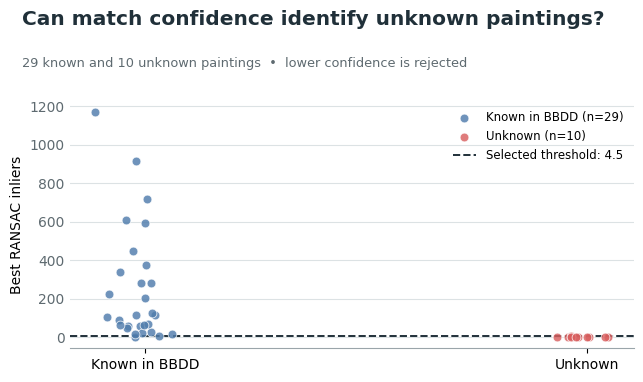

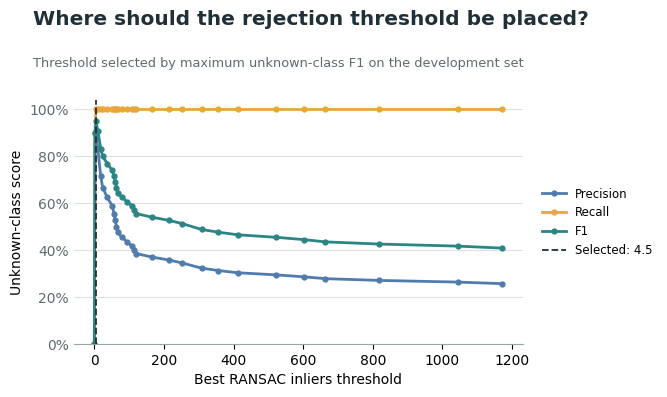

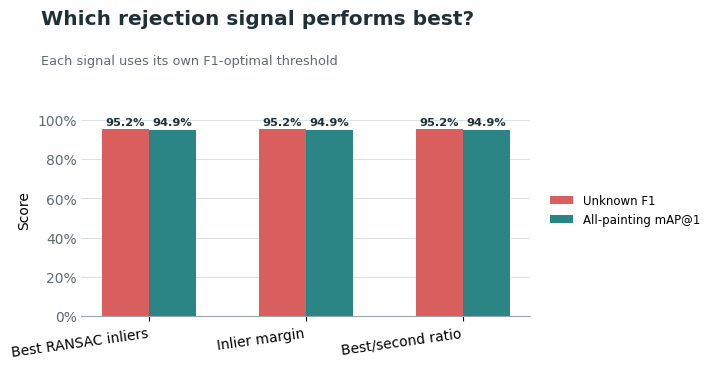

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/unknown_rejection_separation.png
Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/unknown_rejection_threshold_sweep.png
Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/unknown_rejection_signal_comparison.png


In [49]:
# Visualize separation, threshold behaviour and the final signal comparison.
known_color = "#4F7CAC"
unknown_color = "#D95F5F"
rng = np.random.default_rng(7)
selected_scores = rejection_scores[selected_rejection_column].to_numpy(float)
truth_unknown = rejection_scores["unknown"].to_numpy(bool)

fig, axis = plt.subplots(figsize=(6.8, 4.2), facecolor="white")
fig.subplots_adjust(left=0.13, right=0.96, top=0.76, bottom=0.17)
for position, (label, mask, color) in enumerate([
    ("Known in BBDD", ~truth_unknown, known_color),
    ("Unknown", truth_unknown, unknown_color),
]):
    jitter = rng.normal(0, 0.045, int(mask.sum()))
    axis.scatter(
        np.full(int(mask.sum()), position) + jitter, selected_scores[mask],
        s=40, color=color, alpha=0.82, edgecolor="white", linewidth=0.6,
        label=f"{label} (n={int(mask.sum())})", zorder=3,
    )
axis.axhline(
    selected_rejection_threshold, color=DARK, linestyle="--", linewidth=1.4,
    label=f"Selected threshold: {selected_rejection_threshold:.3g}",
)
axis.set_xticks([0, 1], ["Known in BBDD", "Unknown"])
axis.set_ylabel(selected_rejection_signal)
axis.grid(axis="y", color="#DCE2E4", linewidth=0.8)
axis.set_axisbelow(True)
axis.spines[["top", "right", "left"]].set_visible(False)
axis.spines["bottom"].set_color("#9AA5AA")
axis.tick_params(axis="y", length=0, colors="#5E6A70")
axis.legend(loc="upper right", frameon=False, fontsize=8.5)
fig.text(0.06, 0.94, "Can match confidence identify unknown paintings?", fontsize=14.5, fontweight="bold", color=DARK)
fig.text(0.06, 0.84, "29 known and 10 unknown paintings  •  lower confidence is rejected", fontsize=9.3, color="#5E6A70")
rejection_separation_path = output_dir / "unknown_rejection_separation.png"
fig.savefig(rejection_separation_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

selected_sweep = rejection_sweeps[selected_rejection_signal]
fig, axis = plt.subplots(figsize=(6.8, 4.2), facecolor="white")
fig.subplots_adjust(left=0.12, right=0.78, top=0.76, bottom=0.18)
curve_colors = {"precision": "#4F7CAC", "recall": "#E9A63A", "F1": TEAL}
for metric in ("precision", "recall", "F1"):
    axis.plot(
        selected_sweep["threshold"], selected_sweep[metric],
        marker="o", markersize=3.5, linewidth=2,
        color=curve_colors[metric], label=metric.capitalize(),
    )
axis.axvline(
    selected_rejection_threshold, color=DARK, linestyle="--", linewidth=1.3,
    label=f"Selected: {selected_rejection_threshold:.3g}",
)
axis.set_ylim(0, 1.04)
axis.set_yticks(np.linspace(0, 1, 6), [f"{value:.0%}" for value in np.linspace(0, 1, 6)])
axis.set_xlabel(f"{selected_rejection_signal} threshold")
axis.set_ylabel("Unknown-class score")
axis.grid(axis="y", color="#DCE2E4", linewidth=0.8)
axis.set_axisbelow(True)
axis.spines[["top", "right", "left"]].set_visible(False)
axis.spines["bottom"].set_color("#9AA5AA")
axis.tick_params(axis="y", length=0, colors="#5E6A70")
axis.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=8.5)
fig.text(0.06, 0.94, "Where should the rejection threshold be placed?", fontsize=14.5, fontweight="bold", color=DARK)
fig.text(0.06, 0.84, "Threshold selected by maximum unknown-class F1 on the development set", fontsize=9.3, color="#5E6A70")
rejection_sweep_path = output_dir / "unknown_rejection_threshold_sweep.png"
fig.savefig(rejection_sweep_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

fig, axis = plt.subplots(figsize=(6.8, 4.0), facecolor="white")
fig.subplots_adjust(left=0.12, right=0.78, top=0.74, bottom=0.21)
positions = np.arange(len(rejection_summary))
width = 0.30
for offset, metric, label, color in [
    (-0.5, "unknown F1", "Unknown F1", unknown_color),
    (0.5, "mAP@1", "All-painting mAP@1", TEAL),
]:
    values = rejection_summary[metric].to_numpy(float)
    bars = axis.bar(positions + offset * width, values, width, color=color, label=label)
    for bar, value in zip(bars, values):
        axis.text(bar.get_x() + bar.get_width() / 2, value + 0.012, f"{value:.1%}", ha="center", va="bottom", fontsize=8.2, fontweight="bold", color=DARK)
axis.set_xticks(positions, rejection_summary["signal"], rotation=8, ha="right")
axis.set_ylim(0, 1.08)
axis.set_yticks(np.linspace(0, 1, 6), [f"{value:.0%}" for value in np.linspace(0, 1, 6)])
axis.set_ylabel("Score")
axis.grid(axis="y", color="#DCE2E4", linewidth=0.8)
axis.set_axisbelow(True)
axis.spines[["top", "right", "left"]].set_visible(False)
axis.spines["bottom"].set_color("#9AA5AA")
axis.tick_params(axis="y", length=0, colors="#5E6A70")
axis.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=8.5)
fig.text(0.06, 0.94, "Which rejection signal performs best?", fontsize=14.5, fontweight="bold", color=DARK)
fig.text(0.06, 0.84, "Each signal uses its own F1-optimal threshold", fontsize=9.3, color="#5E6A70")
rejection_comparison_path = output_dir / "unknown_rejection_signal_comparison.png"
fig.savefig(rejection_comparison_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print(f"Saved: {rejection_separation_path}")
print(f"Saved: {rejection_sweep_path}")
print(f"Saved: {rejection_comparison_path}")

### Rejection decision

- **Selected rule:** reject a painting when its best database candidate has fewer than **4.5 RANSAC inliers**.
- **Unknown detection:** precision **0.909**, recall **1.000**, F1 **0.952**. All 10 unknown paintings are rejected; one known painting is also rejected.
- **End-to-end retrieval:** **mAP@1 = mAP@5 = mAP@10 = 0.949** across all 39 paintings.
- **Signal comparison:** inlier count, best-minus-second margin and best/second inlier ratio produce the same decisions on this development set.
- **Decision:** use the simpler absolute RANSAC-inlier threshold; it is directly interpretable as a minimum number of geometrically verified correspondences.

## Week 3 vs Week 4 on QSD1-W4

- **Required comparison:** evaluate the selected Week 3 retrieval system on QSD1-W4, then compare it with the selected Week 4 system.
- **End-to-end view:** each week uses its own detection, preprocessing and retrieval decisions.
- **Controlled retrieval view:** both descriptors receive the same refined, rectified Week 4 crops, so the result isolates the retrieval method.
- Report **known-only mAP** separately from **all-painting mAP**, because Week 3 did not include unknown-painting rejection.

In [50]:
# Re-run the exact selected Week 3 colour-texture system on QSD1-W4.
from src.background_removal import detect_painting_mask
from src.colour_texture_retrieval import (
    WEEK3_FINAL_RETRIEVAL,
    describe_colour_images,
    final_retrieval_distances,
)
from src.retrieval import extract_painting, rankings_from_distances
from src.texture_histograms import describe_images

week3_config = WEEK3_FINAL_RETRIEVAL
week3_database_texture = describe_images(bbdd_images, week3_config.texture)
week3_database_colour = describe_colour_images(bbdd_images, week3_config.colour)


def retrieve_with_week3(crops, paintings_per_query, topk=10):
    distances = final_retrieval_distances(
        crops,
        week3_database_texture,
        week3_database_colour,
        week3_config,
    )
    return rankings_from_distances(
        distances, bbdd.ids, paintings_per_query, k=topk
    )


# Week 3 as deployed: its own background removal and rectified painting crops.
week3_crops = []
week3_counts = []
for image in qsd_images:
    _, regions = detect_painting_mask(image)
    query_crops = [extract_painting(image, region) for region in regions]
    week3_crops.extend(query_crops)
    week3_counts.append(len(query_crops))
week3_as_is = retrieve_with_week3(week3_crops, week3_counts)

# Controlled comparison: Week 3 descriptors receive the exact Week 4 crops.
shared_crops = [
    part["crop"] for query_parts in rectified_parts for part in query_parts
]
shared_counts = [len(query_parts) for query_parts in rectified_parts]
week3_shared_crops = retrieve_with_week3(shared_crops, shared_counts)


def regroup_rankings(flat_rankings, counts):
    nested = []
    position = 0
    for count in counts:
        nested.append(flat_rankings[position:position + count])
        position += count
    assert position == len(flat_rankings)
    return nested


# Week 4 before and after the selected unknown-painting rejection rule.
week4_no_rejection = regroup_rankings(
    rejection_scores["verified ranked"].tolist(), shared_counts
)
week4_final = regroup_rankings(
    selected_rejection["rankings"], shared_counts
)


def aligned_painting_lists(nested_rankings, known_only=False):
    rankings, targets = [], []
    for predicted, expected in zip(nested_rankings, ground_truth):
        for painting_position, identifier in enumerate(expected):
            identifier = int(identifier)
            if known_only and identifier == -1:
                continue
            ranking = (
                predicted[painting_position]
                if painting_position < len(predicted)
                else []
            )
            rankings.append([int(value) for value in ranking])
            targets.append([identifier])
    return rankings, targets


def evaluate_week_system(label, nested_rankings):
    all_rankings, all_targets = aligned_painting_lists(nested_rankings)
    known_rankings, known_targets = aligned_painting_lists(
        nested_rankings, known_only=True
    )
    correct_query_counts = sum(
        len(predicted) == len(expected)
        for predicted, expected in zip(nested_rankings, ground_truth)
    )
    row = {
        "system": label,
        "detected paintings": sum(map(len, nested_rankings)),
        "correct query counts": correct_query_counts,
    }
    row.update({
        f"known mAP@{k}": map_at_k(known_rankings, known_targets, k)
        for k in (1, 5, 10)
    })
    row.update({
        f"all mAP@{k}": map_at_k(all_rankings, all_targets, k)
        for k in (1, 5, 10)
    })
    return row


week_comparison_systems = {
    "Week 3 full pipeline": week3_as_is,
    "Week 3 retrieval on shared crops": week3_shared_crops,
    "Week 4 retrieval on shared crops": week4_no_rejection,
    "Week 4 final + unknown rejection": week4_final,
}
week_comparison = pd.DataFrame([
    evaluate_week_system(label, rankings)
    for label, rankings in week_comparison_systems.items()
]).set_index("system")

display(week_comparison.round(3))

,detected paintings,correct query counts,known mAP@1,known mAP@5,known mAP@10,all mAP@1,all mAP@5,all mAP@10
system,,,,,,,,
Week 3 full pipeline,35,24,0.655,0.684,0.688,0.487,0.509,0.511
Week 3 retrieval on shared crops,39,30,0.862,0.908,0.908,0.641,0.675,0.675
Week 4 retrieval on shared crops,39,30,0.931,0.931,0.931,0.692,0.692,0.692
Week 4 final + unknown rejection,39,30,0.931,0.931,0.931,0.949,0.949,0.949


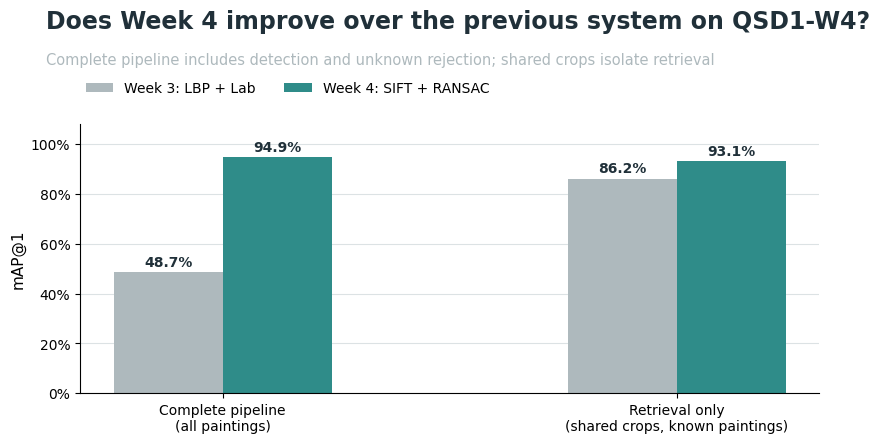

Saved: /Users/femiloye/Desktop/MCV/Materials/C1/project/outputs/week4/week3_vs_week4_qsd1_w4.png


In [51]:
# Two fair views of the required previous-week comparison.
week3_color = "#AEB9BD"
week4_color = "#2F8C89"

comparison_groups = [
    "Complete pipeline\n(all paintings)",
    "Retrieval only\n(shared crops, known paintings)",
]
week3_values = [
    week_comparison.loc["Week 3 full pipeline", "all mAP@1"],
    week_comparison.loc["Week 3 retrieval on shared crops", "known mAP@1"],
]
week4_values = [
    week_comparison.loc["Week 4 final + unknown rejection", "all mAP@1"],
    week_comparison.loc["Week 4 retrieval on shared crops", "known mAP@1"],
]

positions = np.arange(len(comparison_groups))
bar_width = 0.24
figure, axis = plt.subplots(figsize=(8.4, 4.8), facecolor="white")
figure.subplots_adjust(left=0.10, right=0.98, bottom=0.18, top=0.74)

week3_bars = axis.bar(
    positions - bar_width / 2, week3_values, bar_width,
    label="Week 3: LBP + Lab", color=week3_color,
)
week4_bars = axis.bar(
    positions + bar_width / 2, week4_values, bar_width,
    label="Week 4: SIFT + RANSAC", color=week4_color,
)

for bars in (week3_bars, week4_bars):
    for bar in bars:
        value = bar.get_height()
        axis.text(
            bar.get_x() + bar.get_width() / 2, value + 0.012,
            f"{value:.1%}", ha="center", va="bottom",
            fontsize=10, fontweight="bold", color=DARK,
        )

axis.set_xticks(positions, comparison_groups)
axis.set_ylim(0, 1.08)
axis.set_yticks(np.linspace(0, 1, 6))
axis.set_yticklabels([f"{value:.0%}" for value in np.linspace(0, 1, 6)])
axis.set_ylabel("mAP@1", fontsize=11)
axis.grid(axis="y", color="#DCE2E4", linewidth=0.8)
axis.set_axisbelow(True)
axis.spines[["top", "right"]].set_visible(False)
axis.legend(
    loc="upper left", bbox_to_anchor=(0, 1.18), ncol=2,
    frameon=False, fontsize=10, borderaxespad=0,
)

figure.text(
    0.06, 0.94, "SIFT + RANSAC raises end-to-end mAP@1 from 48.7% to 94.9%",
    fontsize=17, fontweight="bold", color=DARK,
)
figure.text(
    0.06, 0.865,
    "Complete pipeline includes detection and unknown rejection; shared crops isolate retrieval",
    fontsize=10.5, color=GREY,
)

comparison_path = output_dir / "week3_vs_week4_qsd1_w4.png"
figure.savefig(comparison_path, dpi=220, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {comparison_path}")